# ResNet-20 on CIFAR-10: versioned targeted attack sweep

This is an **evaluation-only** notebook. It loads the existing `ResNet-20` checkpoints and does not train or modify model weights. It uses the exact architecture and input normalization from the corresponding training notebook.

Run this notebook separately for each architecture. Attach the training notebook output in Kaggle, or set the explicit checkpoint paths below. The loader prints the selected checkpoint path and epoch before evaluation. For unambiguous version control, pin each checkpoint in `MANUAL_CHECKPOINT_PATHS`; strict state-dict loading will reject a checkpoint from a different architecture.

The sweep runs targeted FGSM/FGM and 100-step targeted PGD at Linf budgets 4/255, 8/255, 12/255, 16/255 and L2 budgets 0.5, 1, 2, 3. It writes a CSV and figures under the results directory.


## 1. Imports and reproducibility

In [1]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from IPython.display import display
from torchvision import datasets, transforms


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print('Device:', DEVICE)
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)

Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


## 2. Configuration and output paths

In [2]:
PROJECT_NAME = 'resnet20_targeted_attack_only'

if Path('/kaggle/working').exists():
    WORKING_DIR = Path('/kaggle/working')
else:
    WORKING_DIR = Path.cwd()

DATA_DIR = WORKING_DIR / 'cifar10_data'
RESULTS_DIR = WORKING_DIR / PROJECT_NAME / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

ARCHITECTURE_NAME = 'ResNet20'
TRAINING_MODES = ['clean', 'adv_l2', 'adv_linf']

EPOCHS = 30
ALLOW_PARTIAL_CHECKPOINTS = False

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

MANUAL_CHECKPOINT_ROOT = Path(
    "/kaggle/input/notebooks/amiralimalekloo/"
    "notebookfbf4bae19d/resnet20_targeted_attack_only/results"
)

MANUAL_CHECKPOINT_PATHS = {mode: None for mode in TRAINING_MODES}


print('Results directory:', RESULTS_DIR)

Results directory: /kaggle/working/resnet20_targeted_attack_only/results


## 3. Locate and verify the saved ResNet-20 checkpoints

The original training notebook saved one `last.pt` file per training mode. This
cell searches attached Kaggle inputs and the current working directory, reads
checkpoint metadata, and selects the checkpoint with the largest completed
epoch for each mode.

In [3]:
def infer_training_mode(checkpoint, path):
    signature = checkpoint.get('signature', {})
    mode = signature.get('training_mode')
    if mode in TRAINING_MODES:
        return mode

    path_text = str(path).lower()
    for candidate in TRAINING_MODES:
        if candidate in path_text:
            return candidate

    return None


def checkpoint_state_dict(checkpoint):
    if 'model_state' in checkpoint:
        return checkpoint['model_state']
    if 'state_dict' in checkpoint:
        return checkpoint['state_dict']
    return None


def discover_checkpoints():
    roots = []

    if MANUAL_CHECKPOINT_ROOT is not None:
        roots.append(Path(MANUAL_CHECKPOINT_ROOT))

    for root in (Path('/kaggle/input'), Path('/kaggle/working'), Path.cwd()):
        if root.exists() and root not in roots:
            roots.append(root)

    candidates = {mode: [] for mode in TRAINING_MODES}

    for root in roots:
        for path in root.rglob('*.pt'):
            if path.name.endswith('_progress.pt'):
                continue

            try:
                checkpoint = torch.load(
                    path,
                    map_location='cpu',
                    weights_only=True,
                )
            except Exception:
                continue

            state_dict = checkpoint_state_dict(checkpoint)
            mode = infer_training_mode(checkpoint, path)
            signature = checkpoint.get('signature', {})
            architecture = str(signature.get('architecture', '')).lower()

            if state_dict is None or mode is None:
                continue
            if architecture and 'resnet20' not in architecture:
                continue
            if 'preact' in architecture:
                continue

            epoch = int(checkpoint.get('epoch', -1))
            candidates[mode].append((epoch, path))

    selected = {}
    for mode, mode_candidates in candidates.items():
        if mode_candidates:
            selected[mode] = max(
                mode_candidates,
                key=lambda item: item[0],
            )[1]

    missing = [mode for mode in TRAINING_MODES if mode not in selected and MANUAL_CHECKPOINT_PATHS.get(mode) is None]
    if missing:
        raise FileNotFoundError(
            'Could not find checkpoints for: '
            + ', '.join(missing)
            + '. Attach the previous ResNet-20 notebook output through '
              'Kaggle Input -> Add Input, or set MANUAL_CHECKPOINT_ROOT.'
        )

    for mode, manual_path in MANUAL_CHECKPOINT_PATHS.items():
        if manual_path is not None:
            manual_path = Path(manual_path)
            if not manual_path.is_file():
                raise FileNotFoundError(f'Manual checkpoint for {mode} not found: {manual_path}')
            selected[mode] = manual_path

    return selected


def verify_checkpoints(paths):
    """Every file that will be evaluated must match its label, architecture and epoch.

    Strict state-dict loading only catches shape/name mismatches; it cannot
    tell that a pinned file labelled 'clean' is really the adv_l2 model.
    """
    for mode, path in paths.items():
        checkpoint = torch.load(path, map_location='cpu', weights_only=True)
        signature = checkpoint.get('signature', {})
        epoch = int(checkpoint.get('epoch', -1))

        problems = []
        if signature.get('architecture') != ARCHITECTURE_NAME:
            problems.append(f"architecture is {signature.get('architecture')!r}, "
                            f"expected {ARCHITECTURE_NAME!r}")
        if signature.get('training_mode') != mode:
            problems.append(f"training mode in file is "
                            f"{signature.get('training_mode')!r}, expected {mode!r}")
        if epoch < EPOCHS and not ALLOW_PARTIAL_CHECKPOINTS:
            problems.append(f'only {epoch}/{EPOCHS} epochs completed')
        if problems:
            raise RuntimeError(f'Checkpoint problem for {mode}: {path}\n  '
                               + '\n  '.join(problems))
        print(f'verified {mode:8s} | epoch {epoch}/{EPOCHS} | {path}')
        del checkpoint


CHECKPOINT_PATHS = discover_checkpoints()
verify_checkpoints(CHECKPOINT_PATHS)

verified clean    | epoch 30/30 | /kaggle/input/notebooks/amiralimalekloo/notebook8f262524ba/cifar10_resnet20_robustness/checkpoints/clean/last.pt
verified adv_l2   | epoch 30/30 | /kaggle/input/notebooks/amiralimalekloo/notebook8f262524ba/cifar10_resnet20_robustness/checkpoints/adv_l2/last.pt
verified adv_linf | epoch 30/30 | /kaggle/input/notebooks/amiralimalekloo/notebook8f262524ba/cifar10_resnet20_robustness/checkpoints/adv_linf/last.pt


## 4. CIFAR-10 test data

In [4]:
test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)
CLASS_NAMES = test_dataset.classes

print('Test images:', len(test_dataset))
print('Classes:', CLASS_NAMES)

100%|██████████| 170M/170M [27:15<00:00, 104kB/s]


Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 5. ResNet-20 architecture

This must match the training notebook exactly so that the saved weights load.

In [5]:
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, images):
        return (images - self.mean) / self.std

class CifarBasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride == 1 and in_channels == out_channels:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        residual = self.shortcut(x)

        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        x = F.relu(x + residual)

        return x


class ResNet20(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
        )

        self.stage1 = self._make_stage(16, 16, stride=1)
        self.stage2 = self._make_stage(16, 32, stride=2)
        self.stage3 = self._make_stage(32, 64, stride=2)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, num_classes)

        self._initialize_weights()

    @staticmethod
    def _make_stage(in_channels, out_channels, stride):
        return nn.Sequential(
            CifarBasicBlock(in_channels, out_channels, stride),
            CifarBasicBlock(out_channels, out_channels),
            CifarBasicBlock(out_channels, out_channels),
        )

    def _initialize_weights(self):
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(
                    layer.weight,
                    mode='fan_out',
                    nonlinearity='relu',
                )
            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)
            elif isinstance(layer, nn.Linear):
                nn.init.normal_(layer.weight, mean=0.0, std=0.01)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)


def build_model(pretrained=False):
    del pretrained
    backbone = ResNet20(num_classes=10)
    return nn.Sequential(
        Normalize(CIFAR10_MEAN, CIFAR10_STD),
        backbone,
    )

## 6. Load the three trained models

In [6]:
def load_resnet20(training_mode):
    checkpoint = torch.load(
        CHECKPOINT_PATHS[training_mode], map_location='cpu', weights_only=True
    )
    state_dict = checkpoint_state_dict(checkpoint)
    model = build_model(pretrained=False)

    # Also support checkpoints saved from nn.DataParallel.
    if all(key.startswith('module.') for key in state_dict):
        state_dict = {
            key.removeprefix('module.'): value for key, value in state_dict.items()
        }

    model.load_state_dict(state_dict, strict=True)
    return model.to(DEVICE).eval(), checkpoint.get('epoch')


def load_all_models():
    models = {}
    for mode in TRAINING_MODES:
        models[mode], epoch = load_resnet20(mode)
        print(f'Loaded {mode:8s} | epoch {epoch}')
    return models

## 7. Attack study configuration

Four test images, two wrong target classes per image (the easiest and the
hardest, ranked by the clean model's logits), several epsilons per norm, and
two attacks side by side: single-step FGSM (Linf) / FGM (L2) and PGD with 100
steps. Every attack maximizes `log p(target)`, i.e. the target confidence.

In [7]:
# Samples, targets and budgets
NORMS = ('linf', 'l2')
EPSILONS = {
    'linf': [5 / 255, 10 / 255, 15 / 255, 20 / 255, 25/255],
    'l2':   [1.0, 4.0, 8.0, 12.0, 16.0],
}

# Epsilon each adversarially trained model was trained with (dotted line in plots).
TRAIN_EPS = {'linf': 8 / 255, 'l2': 0.8}

NOTEBOOK_VERSION = 'attack-sweep v2'
N_SAMPLES = 4          # test images, correctly classified by all three models
CONF_GOAL = 0.99       # target-confidence goal

# PGD: all steps are run; the best iterate (highest log p(target)) is kept.
PGD_STEPS = 100
PGD_RESTARTS = 3       # raise to 3 if PGD plateaus below the goal
PGD_PEAK_STEP = 0.10   # first step = 10% of epsilon, cosine-decayed to ~0

from datetime import datetime

# Set RUN_ID manually to rerun into the same folder; otherwise each run is kept.
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
STUDY_DIR = RESULTS_DIR / 'attack_sweeps' / RUN_ID
STUDY_DIR.mkdir(parents=True, exist_ok=True)

print('Linf epsilons:', [f'{round(e * 255)}/255' for e in EPSILONS['linf']])
print('L2 epsilons  :', EPSILONS['l2'])
print('PGD steps    :', PGD_STEPS, '| restarts:', PGD_RESTARTS)
print('Run folder   :', STUDY_DIR)

Linf epsilons: ['5/255', '10/255', '15/255', '20/255', '25/255']
L2 epsilons  : [1.0, 4.0, 8.0, 12.0, 16.0]
PGD steps    : 100 | restarts: 3
Run folder   : /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842


## 8. Targeted FGSM/FGM and PGD

Both attacks use the same signature `attack(model, images, targets, norm, epsilon)`
and the same objective. FGSM/FGM take one full-size step. PGD runs all steps with
a cosine-decayed step size tied to epsilon and keeps the iterate with the highest
target probability.

In [8]:
def batch_l2_norm(tensor):
    return tensor.flatten(1).norm(p=2, dim=1).view(-1, 1, 1, 1)


def normalized_gradient(gradient, norm):
    if norm == 'linf':
        return gradient.sign()
    if norm == 'l2':
        return gradient / batch_l2_norm(gradient).clamp_min(1e-12)
    raise ValueError(f'Unsupported norm: {norm}')


def project_perturbation(delta, norm, epsilon):
    if norm == 'linf':
        return delta.clamp(-epsilon, epsilon)
    if norm == 'l2':
        scale = epsilon / batch_l2_norm(delta).clamp_min(1e-12)
        return delta * scale.clamp(max=1.0)
    raise ValueError(f'Unsupported norm: {norm}')


def random_perturbation(images, norm, epsilon):
    if norm == 'linf':
        return torch.empty_like(images).uniform_(-epsilon, epsilon)
    if norm == 'l2':
        direction = torch.randn_like(images)
        direction = direction / batch_l2_norm(direction).clamp_min(1e-12)
        radius = torch.rand(
            images.size(0), 1, 1, 1, device=images.device, dtype=images.dtype
        ).pow(1.0 / images[0].numel())
        return epsilon * radius * direction
    raise ValueError(f'Unsupported norm: {norm}')


def target_log_prob(logits, targets):
    """log p(target | image). Every attack below maximizes this."""
    return F.log_softmax(logits, dim=1).gather(1, targets[:, None]).squeeze(1)


def fgsm_attack(model, images, targets, norm, epsilon):
    """Targeted single-step attack: FGSM for Linf, FGM for L2.

    One gradient step of full size epsilon toward the target class.
    Returns (adversarial_images, None); there is no trajectory for one step.
    """
    model.eval()
    with torch.enable_grad():
        adv = images.detach().clone().requires_grad_(True)
        logp = target_log_prob(model(adv), targets)
        grad = torch.autograd.grad(logp.sum(), adv)[0]

    delta = project_perturbation(
        epsilon * normalized_gradient(grad, norm), norm, epsilon
    )
    return (images + delta).clamp(0, 1).detach(), None


def pgd_attack(model, images, targets, norm, epsilon,
               steps=None, restarts=None):
    """Targeted PGD that maximizes target confidence.

    Runs every step (no early stopping) and returns, per image, the iterate
    with the highest log p(target). Also returns the best-so-far target
    probability after each step, shape [steps, batch].
    """
    steps = PGD_STEPS if steps is None else steps          # read config at call time
    restarts = PGD_RESTARTS if restarts is None else restarts
    model.eval()
    images = images.detach()
    best_images = images.clone()
    best_logp = torch.full((images.size(0),), -float('inf'),
                           device=images.device)
    trajectory = []

    def keep_if_better(candidates, logp):
        better = logp > best_logp
        best_images[better] = candidates[better]
        best_logp[better] = logp[better]

    for _ in range(restarts):
        adv = (images + random_perturbation(images, norm, epsilon)).clamp(0, 1)
        trajectory = []

        for step in range(steps):
            with torch.enable_grad():
                adv = adv.detach().requires_grad_(True)
                logp = target_log_prob(model(adv), targets)
                # .sum() (not .mean()) keeps per-image gradients at full scale
                grad = torch.autograd.grad(logp.sum(), adv)[0]

            keep_if_better(adv.detach(), logp.detach())
            trajectory.append(best_logp.exp().cpu())

            alpha = (PGD_PEAK_STEP * epsilon
                     * 0.5 * (1 + math.cos(math.pi * step / steps)))
            with torch.no_grad():
                adv = adv.detach() + alpha * normalized_gradient(grad, norm)
                delta = project_perturbation(adv - images, norm, epsilon)
                adv = (images + delta).clamp(0, 1)

        with torch.no_grad():                    # score the last iterate too
            keep_if_better(adv, target_log_prob(model(adv), targets))

    return best_images.detach(), torch.stack(trajectory)


ATTACK_FUNCTIONS = {'fgsm': fgsm_attack, 'pgd': pgd_attack}


def attack_label(attack, norm):
    if attack == 'pgd':
        return f'PGD-{PGD_STEPS}'
    return 'FGSM' if norm == 'linf' else 'FGM'


def eps_label(norm, eps):
    return f'{round(eps * 255)}/255' if norm == 'linf' else f'{eps:g}'

## 9. Sample selection and experiment loop

The same sample-target pairs are used for every model. After each attack the
code asserts that the perturbation respects the epsilon budget and the [0, 1]
pixel range.

In [9]:
import random

def select_study_pairs(models):
    """
    Pick N_SAMPLES test images that ALL models classify correctly
    (distinct true classes).

    For each image, choose two completely random, distinct target classes
    different from the true label.

    The same target pairs are used for every model.
    """
    chosen, used_classes = [], set()

    with torch.no_grad():
        for idx in range(len(test_dataset)):
            image, label = test_dataset[idx]

            if label in used_classes:
                continue

            x = image[None].to(DEVICE)

            if all(m(x).argmax(1).item() == label for m in models.values()):
                chosen.append(idx)
                used_classes.add(label)

            if len(chosen) == N_SAMPLES:
                break

    pairs = []

    for idx in chosen:
        image, label = test_dataset[idx]

        # All possible wrong target classes
        possible_targets = [
            c for c in range(10)
            if c != label
        ]

        # Pick two distinct random wrong targets
        target1, target2 = random.sample(possible_targets, 2)

        pairs.append((idx, label, target1, 'random_1'))
        pairs.append((idx, label, target2, 'random_2'))

    return pairs


def run_study(models):
    pairs = select_study_pairs(models)
    if len(pairs) < 2 * N_SAMPLES:
        print('Warning: fewer common correctly classified samples than requested.')

    images = torch.stack([test_dataset[p[0]][0] for p in pairs]).to(DEVICE)
    targets = torch.tensor([p[2] for p in pairs], device=DEVICE)

    rows, adv_store, traj_store = [], {}, {}
    for mode, model in models.items():
        for norm in NORMS:
            for eps in EPSILONS[norm]:
                for attack, attack_fn in ATTACK_FUNCTIONS.items():
                    set_seed(SEED)
                    adv, trajectory = attack_fn(model, images, targets, norm, eps)

                    # The perturbation must respect the budget and pixel range.
                    delta = (adv - images).flatten(1)
                    linf_used = delta.abs().max(1).values
                    l2_used = delta.norm(dim=1)
                    used = linf_used if norm == 'linf' else l2_used
                    assert adv.min().item() >= 0 and adv.max().item() <= 1
                    assert used.max().item() <= eps + 1e-5, (
                        f'{mode} {norm} {attack}: budget exceeded')

                    with torch.no_grad():
                        probs = F.softmax(model(adv), dim=1)

                    for k, (idx, label, target, kind) in enumerate(pairs):
                        conf = probs[k, target].item()
                        pred = probs[k].argmax().item()
                        rows.append({
                            'model': mode, 'norm': norm, 'attack': attack,
                            'epsilon': eps, 'eps_label': eps_label(norm, eps),
                            'pair': k, 'sample_index': idx,
                            'true': CLASS_NAMES[label],
                            'target': CLASS_NAMES[target],
                            'target_kind': kind,
                            'target_conf': conf,
                            'pred': CLASS_NAMES[pred],
                            'hit_target': pred == target,
                            'reached_goal': conf >= CONF_GOAL,
                            'linf_used': linf_used[k].item(),
                            'l2_used': l2_used[k].item(),
                        })

                    adv_store[(mode, norm, eps, attack)] = adv.cpu()
                    if trajectory is not None:
                        traj_store[(mode, norm, eps, attack)] = trajectory

                    mean_conf = probs[torch.arange(len(pairs), device=DEVICE), targets].mean().item()
                    print(f'{mode:8s} {norm:4s} eps={eps_label(norm, eps):>6s} '
                          f'{attack_label(attack, norm):8s} | '
                          f'mean target confidence {100 * mean_conf:5.1f}%')

    table = pd.DataFrame(rows)
    table.to_csv(STUDY_DIR / 'confidence_study.csv', index=False)
    return table, pairs, images.cpu(), adv_store, traj_store


def summarize(table):
    """Mean target confidence per (model, norm, attack, eps) and how many of
    the sample-target pairs reached CONF_GOAL."""
    keys = ['model', 'norm', 'attack', 'eps_label']
    summary = (table.groupby(keys + ['target_kind']).target_conf.mean()
               .unstack('target_kind').mul(100).round(1)
               .add_prefix('conf% '))
    summary['pairs at goal'] = table.groupby(keys).reached_goal.sum().astype(int)
    summary['pairs total'] = table.groupby(keys).size()

    order = pd.MultiIndex.from_tuples(
        [(m, n, a, eps_label(n, e))
         for m in TRAINING_MODES for n in NORMS
         for e in EPSILONS[n] for a in ATTACK_FUNCTIONS],
        names=keys)
    summary = summary.reindex(order)
    summary.to_csv(STUDY_DIR / 'confidence_summary.csv')
    return summary

import hashlib
import json


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for block in iter(lambda: file.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def write_run_manifest(pairs):
    """Record exactly what produced this run's CSV and figures."""
    checkpoints = {}
    for mode, path in CHECKPOINT_PATHS.items():
        checkpoint = torch.load(path, map_location='cpu', weights_only=True)
        signature = checkpoint.get('signature', {})
        checkpoints[mode] = {
            'path': str(path),
            'sha256': sha256_of(path),
            'epoch': checkpoint.get('epoch'),
            'architecture': signature.get('architecture'),
            'training_mode_in_file': signature.get('training_mode'),
        }
        del checkpoint

    manifest = {
        'notebook_version': NOTEBOOK_VERSION,
        'run_id': RUN_ID,
        'torch': torch.__version__,
        'device': str(DEVICE),
        'seed': SEED,
        'checkpoints': checkpoints,
        'epsilons': {n: [eps_label(n, e) for e in EPSILONS[n]] for n in NORMS},
        'training_epsilon': {n: eps_label(n, TRAIN_EPS[n]) for n in NORMS},
        'n_samples': N_SAMPLES,
        'conf_goal': CONF_GOAL,
        'pgd': {'steps': PGD_STEPS, 'restarts': PGD_RESTARTS,
                'peak_step_fraction': PGD_PEAK_STEP},
        'pairs': [
            {'test_index': idx, 'true': CLASS_NAMES[label],
             'target': CLASS_NAMES[target], 'kind': kind}
            for idx, label, target, kind in pairs
        ],
    }
    with open(STUDY_DIR / 'run_manifest.json', 'w', encoding='utf-8') as file:
        json.dump(manifest, file, indent=2)
    print('Wrote', STUDY_DIR / 'run_manifest.json')
    return manifest


## 10. Plotting helpers

In [10]:
LINESTYLES = {'fgsm': '--', 'pgd': '-'}


def plot_confidence_vs_epsilon(table):
    for norm in NORMS:
        scale = 255 if norm == 'linf' else 1
        xlabel = 'epsilon (x / 255)' if norm == 'linf' else 'epsilon (L2)'
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)

        for ax, kind in zip(axes, ('easiest', 'hardest')):
            for i, mode in enumerate(TRAINING_MODES):
                for attack, linestyle in LINESTYLES.items():
                    sub = table[(table.norm == norm) & (table.model == mode)
                                & (table.target_kind == kind)
                                & (table.attack == attack)]
                    mean_conf = sub.groupby('epsilon').target_conf.mean()
                    ax.plot(mean_conf.index * scale, 100 * mean_conf.values,
                            linestyle=linestyle, marker='o', color=f'C{i}',
                            label=f'{mode} {attack_label(attack, norm)}')
            ax.axhline(100 * CONF_GOAL, ls=':', c='gray', lw=1)
            ax.axvline(TRAIN_EPS[norm] * scale, ls=':', c='k', lw=0.8)
            ax.set_title(f'{norm}: {kind} wrong target (mean over samples)')
            ax.set_xlabel(xlabel + '   [black dotted: training eps]')
            ax.set_ylim(0, 102)
            ax.grid(alpha=0.3)

        axes[0].set_ylabel('Target confidence (%)')
        axes[1].legend(fontsize=7, ncol=2)
        fig.tight_layout()
        fig.savefig(STUDY_DIR / f'confidence_vs_eps_{norm}.png', dpi=160)
        plt.show()
        plt.close(fig)


def plot_adversarial_grid(table, pairs, images, adv_store, mode, norm):
    """Rows: sample-target pairs. Columns: original, then FGSM and PGD at each epsilon."""
    eps_list = EPSILONS[norm]
    n_cols = 1 + len(eps_list) * len(ATTACK_FUNCTIONS)
    fig, axes = plt.subplots(len(pairs), n_cols,
                             figsize=(1.9 * n_cols, 2.4 * len(pairs)),
                             squeeze=False)
    sub_all = table[(table.model == mode) & (table.norm == norm)]

    for r, (idx, label, target, kind) in enumerate(pairs):
        axes[r, 0].imshow(images[r].permute(1, 2, 0).numpy())
        axes[r, 0].set_title(
            f'{CLASS_NAMES[label]} -> {CLASS_NAMES[target]}\n({kind} target)',
            fontsize=6)

        col = 1
        for eps in eps_list:
            for attack in ATTACK_FUNCTIONS:
                row = sub_all[(sub_all.attack == attack)
                              & (sub_all.epsilon == eps)
                              & (sub_all.pair == r)].iloc[0]
                axes[r, col].imshow(
                    adv_store[(mode, norm, eps, attack)][r]
                    .permute(1, 2, 0).numpy())
                axes[r, col].set_title(
                    f'{attack_label(attack, norm)} {row.eps_label}\n'
                    f'pred: {row.pred}\ntarget {100 * row.target_conf:.1f}%',
                    fontsize=6)
                col += 1

    for ax in axes.flat:
        ax.axis('off')
    fig.suptitle(f'{mode} | targeted attacks | {norm}', fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(STUDY_DIR / f'grid_{mode}_{norm}.png', dpi=130,
                bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_trajectories(traj_store, mode, norm):
    """PGD only: best target confidence so far at every step."""
    eps_list = EPSILONS[norm]
    fig, axes = plt.subplots(1, len(eps_list),
                             figsize=(3.6 * len(eps_list), 3),
                             sharey=True, squeeze=False)
    for ax, eps in zip(axes[0], eps_list):
        trajectory = 100 * traj_store[(mode, norm, eps, 'pgd')].numpy()
        ax.plot(trajectory, lw=1)               # one line per sample-target pair
        ax.axhline(100 * CONF_GOAL, ls=':', c='gray', lw=1)
        ax.set_title(f'eps {eps_label(norm, eps)}', fontsize=9)
        ax.set_xlabel('PGD step')
        ax.set_ylim(0, 102)
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel('Best target confidence so far (%)')
    fig.suptitle(f'{mode} | {norm}: PGD confidence vs step', fontsize=10)
    fig.tight_layout()
    fig.savefig(STUDY_DIR / f'trajectory_{mode}_{norm}.png', dpi=140)
    plt.show()
    plt.close(fig)

## 11. Run the study

No training happens here: the saved checkpoints are loaded and evaluated.

In [11]:
models = load_all_models()
table, pairs, study_images, adv_store, traj_store = run_study(models)
write_run_manifest(pairs)

summary = summarize(table)
display(summary)

Loaded clean    | epoch 30
Loaded adv_l2   | epoch 30
Loaded adv_linf | epoch 30
clean    linf eps= 5/255 FGSM     | mean target confidence   7.4%
clean    linf eps= 5/255 PGD-100  | mean target confidence 100.0%
clean    linf eps=10/255 FGSM     | mean target confidence   4.4%
clean    linf eps=10/255 PGD-100  | mean target confidence 100.0%
clean    linf eps=15/255 FGSM     | mean target confidence   1.1%
clean    linf eps=15/255 PGD-100  | mean target confidence 100.0%
clean    linf eps=20/255 FGSM     | mean target confidence   1.0%
clean    linf eps=20/255 PGD-100  | mean target confidence 100.0%
clean    linf eps=25/255 FGSM     | mean target confidence   1.0%
clean    linf eps=25/255 PGD-100  | mean target confidence 100.0%
clean    l2   eps=     1 FGM      | mean target confidence   4.6%
clean    l2   eps=     1 PGD-100  | mean target confidence 100.0%
clean    l2   eps=     4 FGM      | mean target confidence   5.1%
clean    l2   eps=     4 PGD-100  | mean target confidence 10

target_kind                     conf% random_1  conf% random_2  pairs at goal  \
model    norm attack eps_label                                                  
clean    linf fgsm   5/255                10.0             4.8              0   
              pgd    5/255               100.0           100.0              8   
              fgsm   10/255                5.1             3.7              0   
              pgd    10/255              100.0           100.0              8   
              fgsm   15/255                1.1             1.1              0   
              pgd    15/255              100.0           100.0              8   
              fgsm   20/255                1.4             0.7              0   
              pgd    20/255              100.0           100.0              8   
              fgsm   25/255                1.2             0.7              0   
              pgd    25/255              100.0           100.0              8   
         l2   fgsm   1                     6.6             2.5              0   
              pgd    1                   100.0           100.0              8   
              fgsm   4                     2.1             8.2              0   
              pgd    4                   100.0           100.0              8   
              fgsm   8                     2.8             3.8              0   
              pgd    8                   100.0           100.0              8   
              fgsm   12                    0.9             2.6              0   
              pgd    12                  100.0           100.0              8   
              fgsm   16                    0.8             2.2              0   
              pgd    16                  100.0           100.0              8   
adv_l2   linf fgsm   5/255                 4.0             2.1              0   
              pgd    5/255                 4.6             2.3              0   
              fgsm   10/255               11.7             6.6              0   
              pgd    10/255               19.6            10.8              0   
              fgsm   15/255               24.2            13.6              0   
              pgd    15/255               59.3            33.4              0   
              fgsm   20/255               37.2            20.9              0   
              pgd    20/255               78.1            59.6              0   
              fgsm   25/255               48.0            28.3              0   
              pgd    25/255               92.7            72.0              5   
         l2   fgsm   1                     5.5             3.0              0   
              pgd    1                     7.2             3.8              0   
              fgsm   4                    51.8            32.3              0   
              pgd    4                    98.6            73.3              5   
              fgsm   8                    68.0            50.5              0   
              pgd    8                   100.0            97.8              6   
              fgsm   12                   66.0            46.2              0   
              pgd    12                  100.0            99.6              8   
              fgsm   16                   59.2            41.1              0   
              pgd    16                  100.0            99.8              8   
adv_linf linf fgsm   5/255                 2.0             1.7              0   
              pgd    5/255                 2.1             1.8              0   
              fgsm   10/255                4.4             3.1              0   
              pgd    10/255                6.0             4.0              0   
              fgsm   15/255                8.9             5.2              0   
              pgd    15/255               19.6            11.3              0   
              fgsm   20/255               15.6             7.7              0   
              pgd    20/255    

## 12. Figures

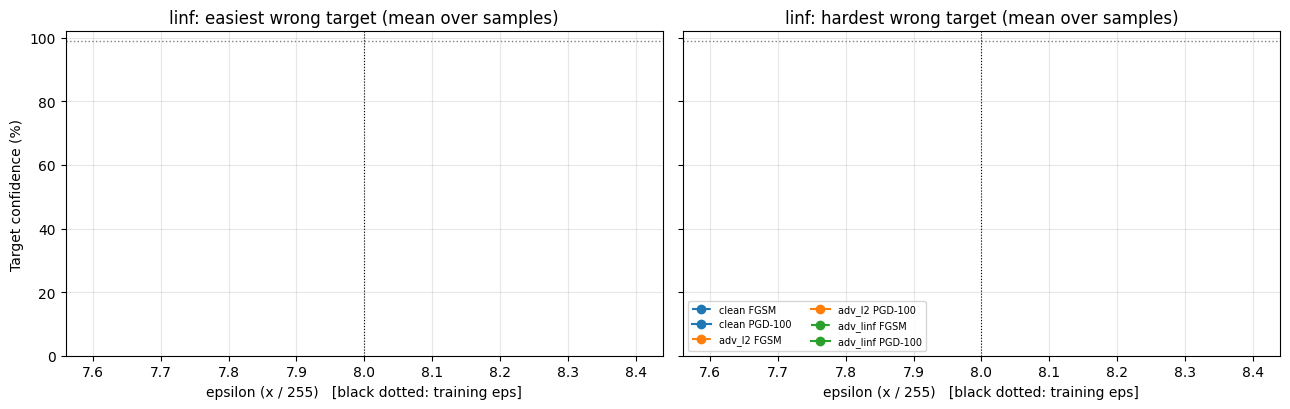

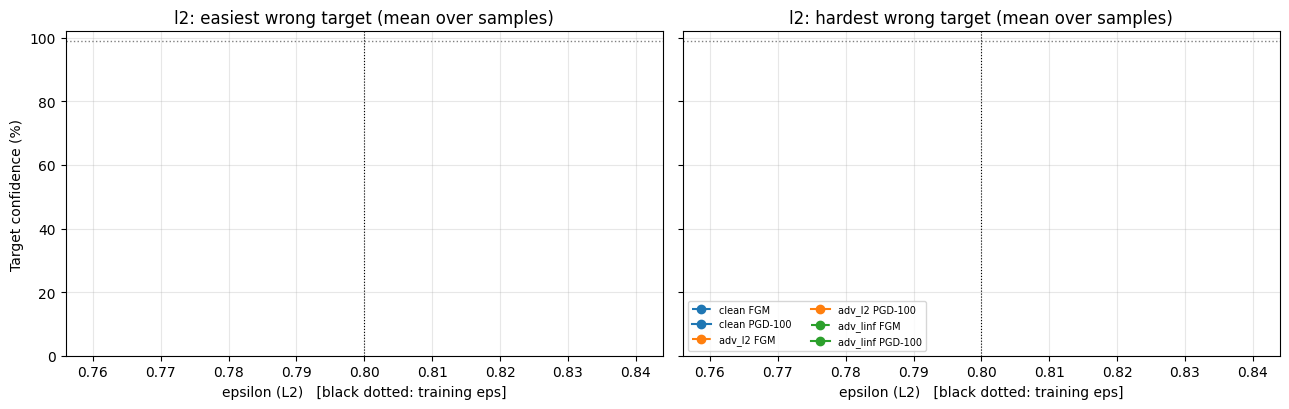

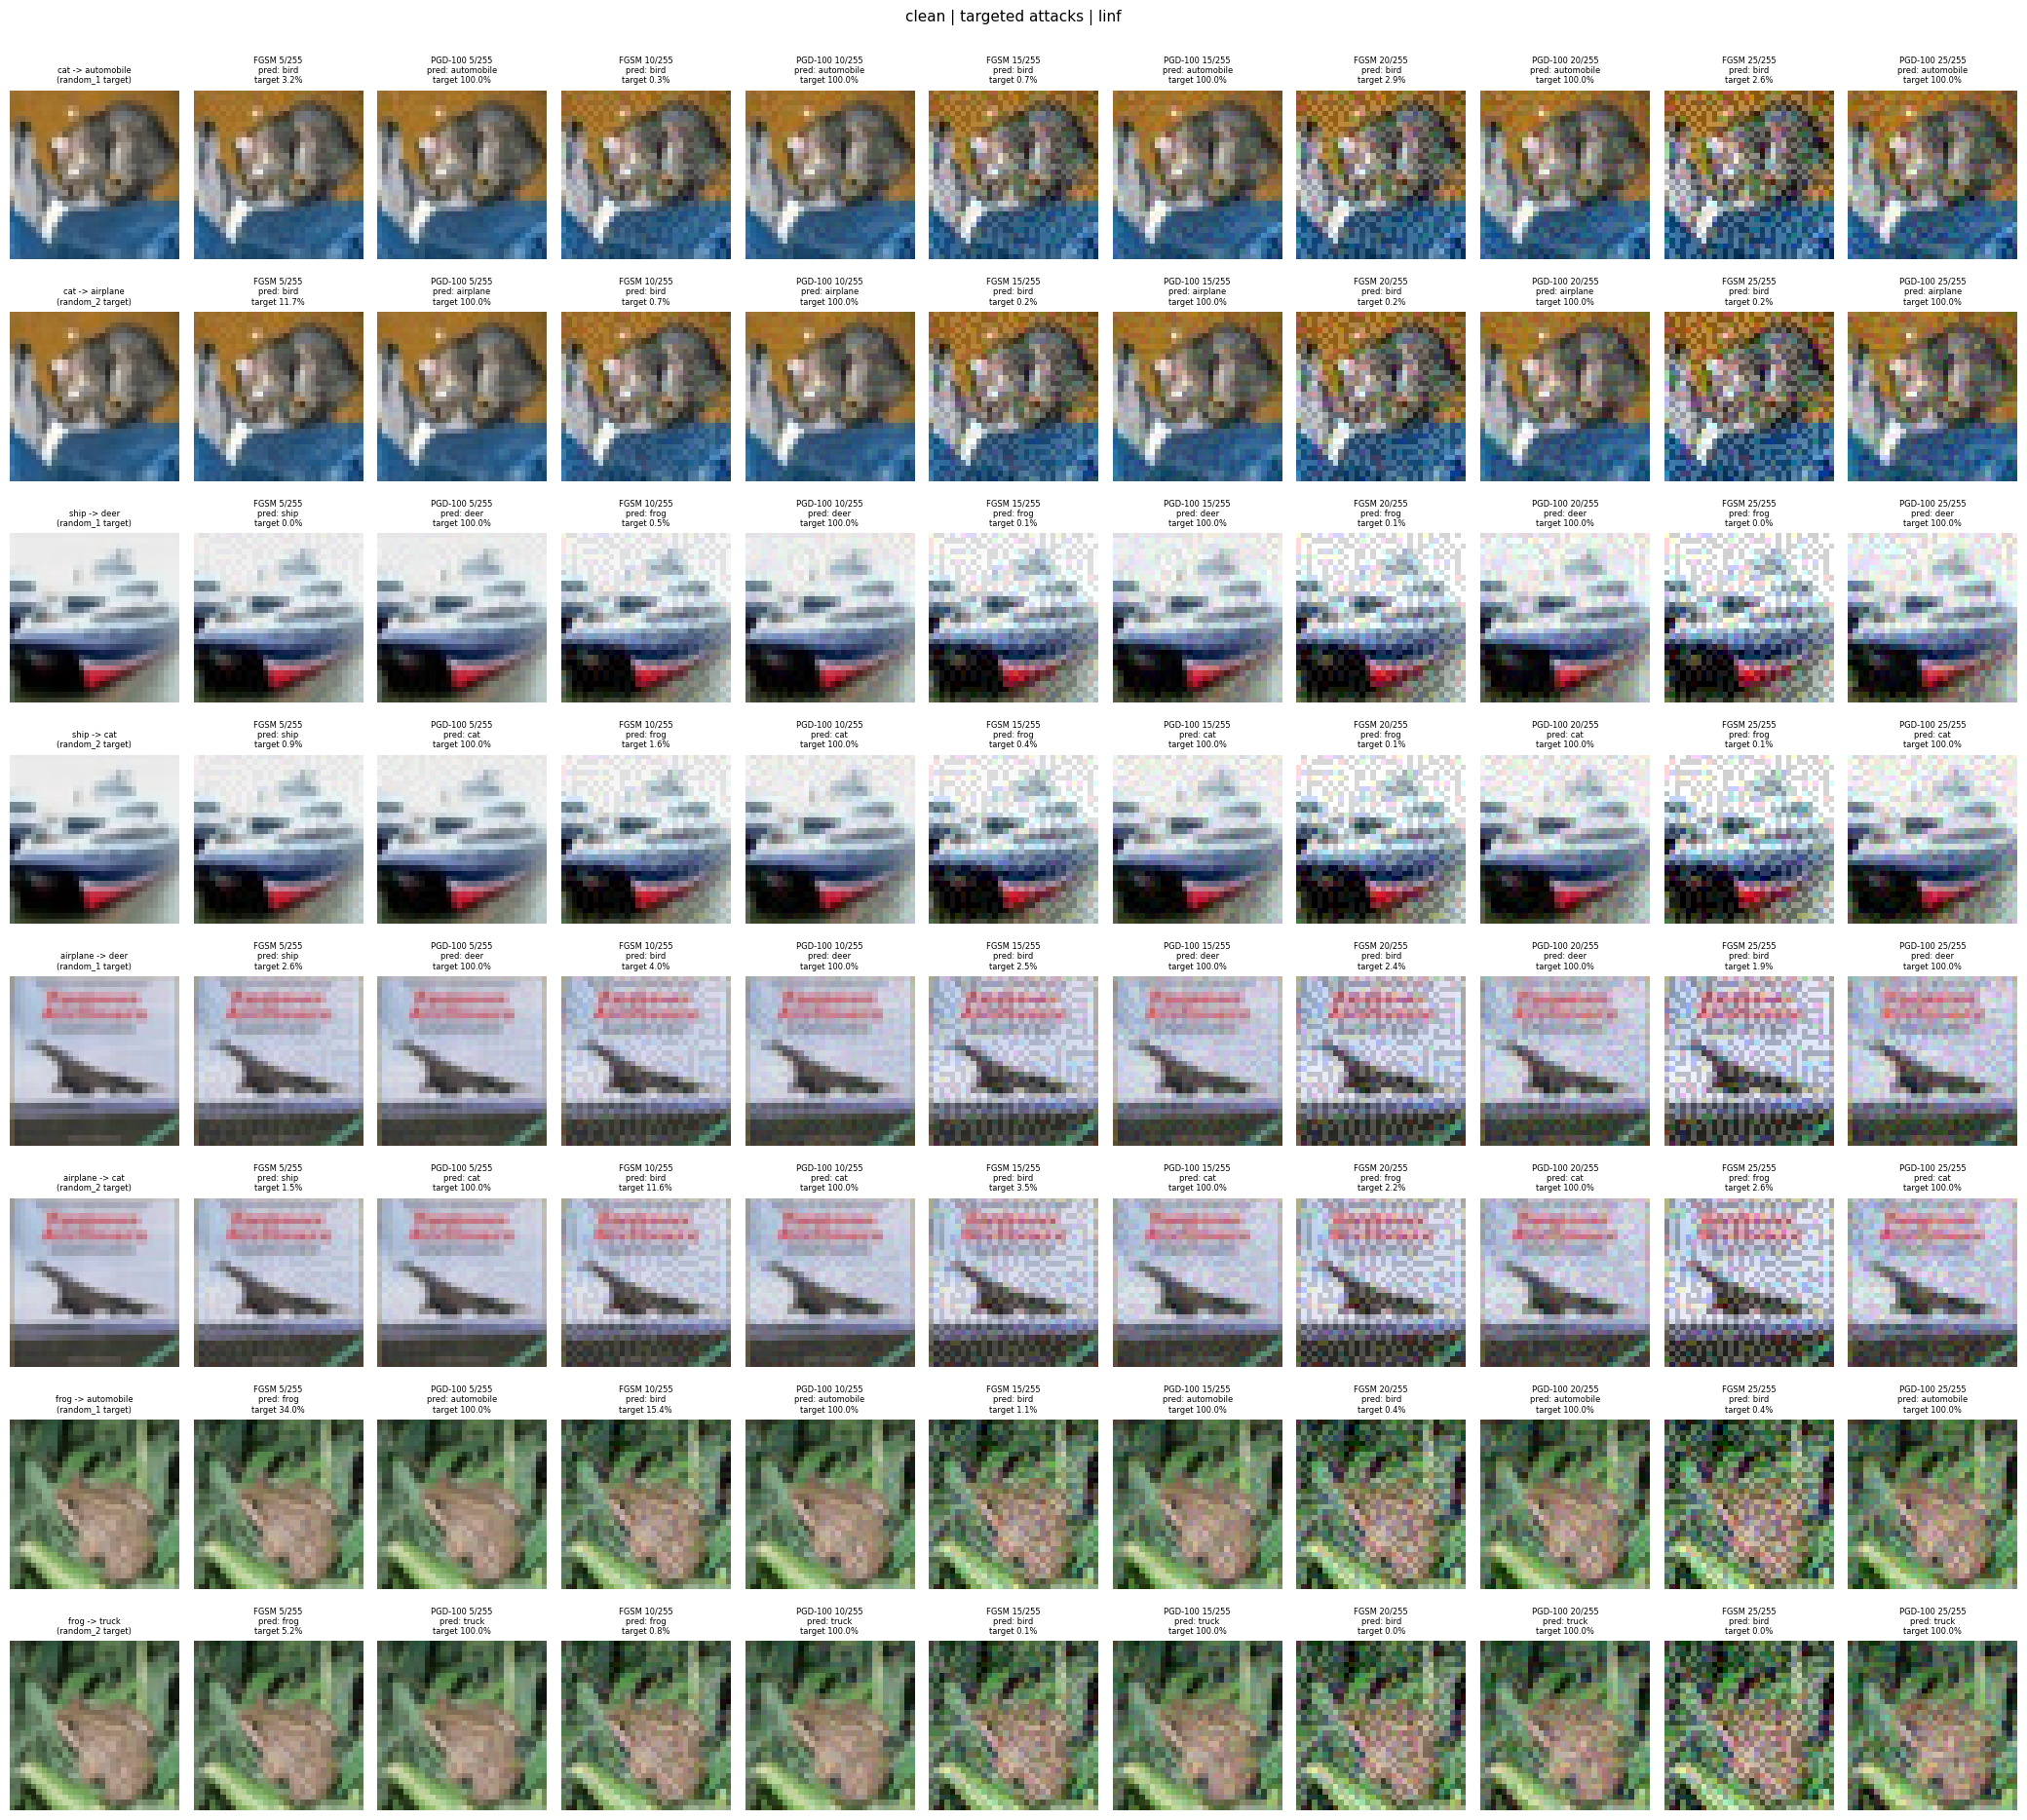

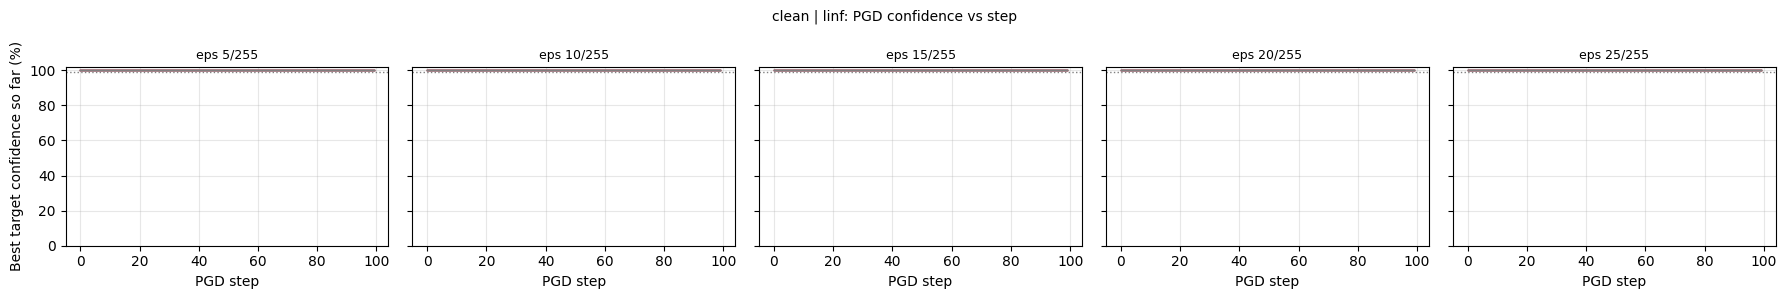

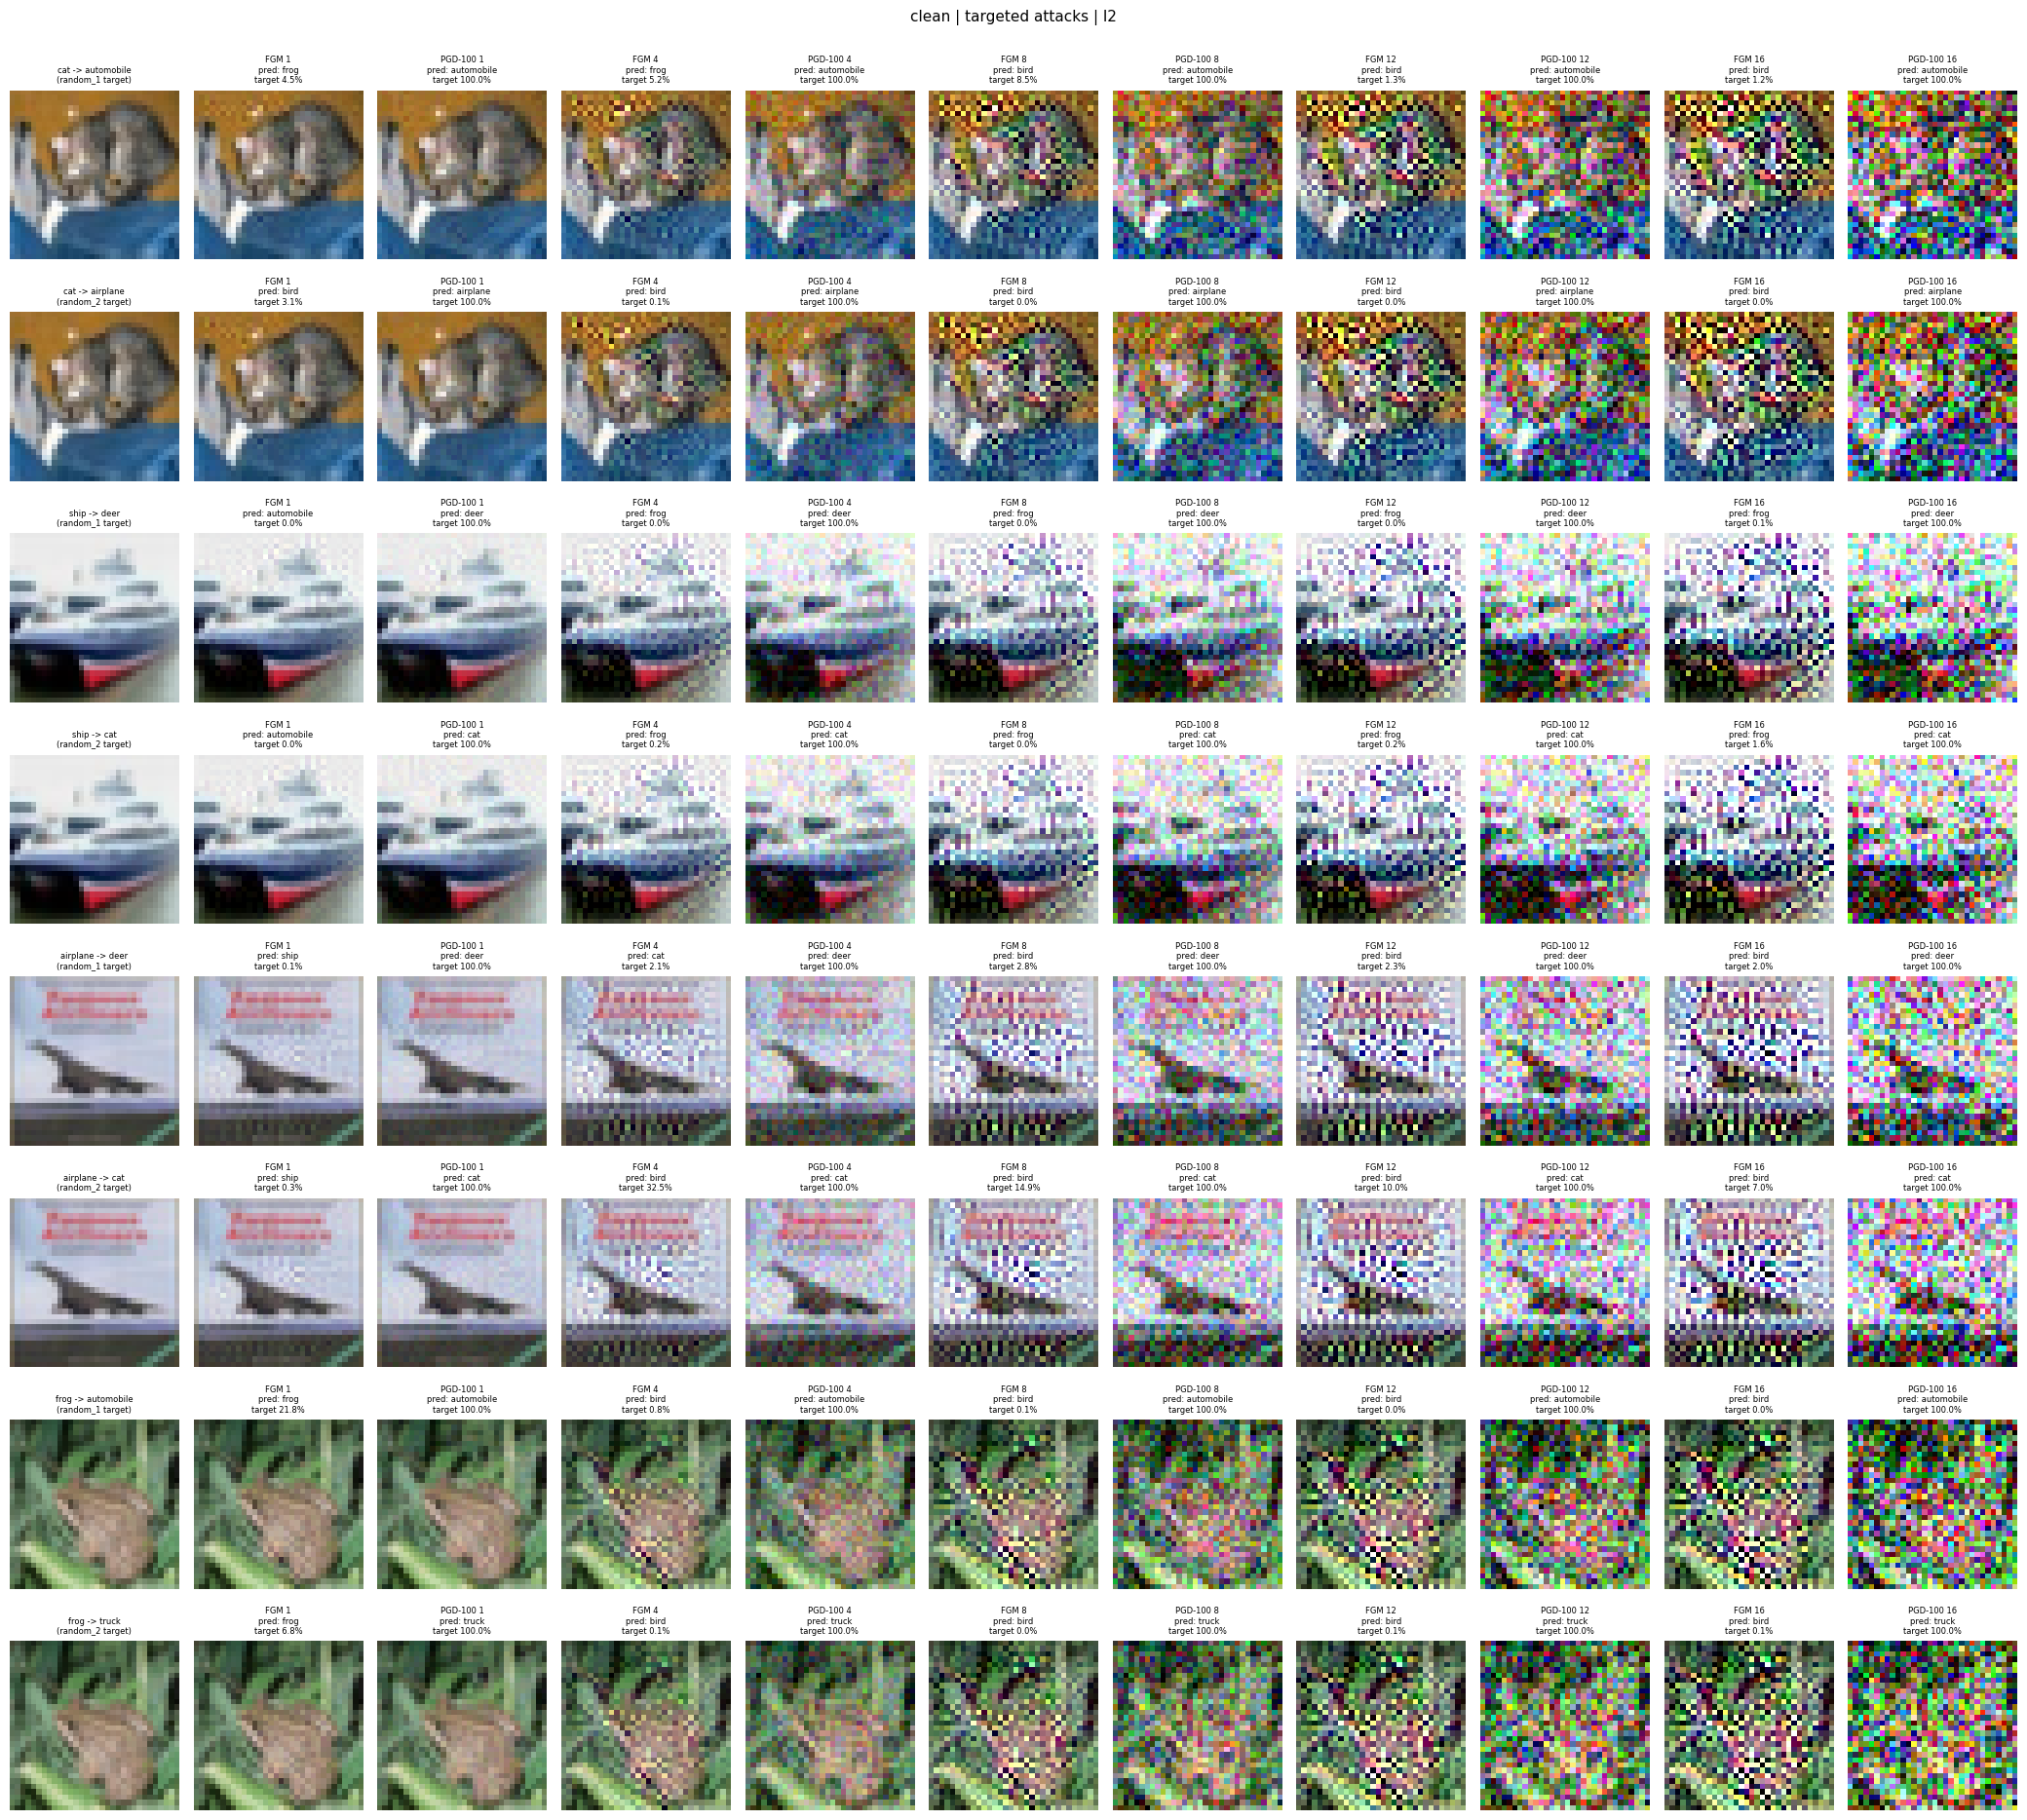

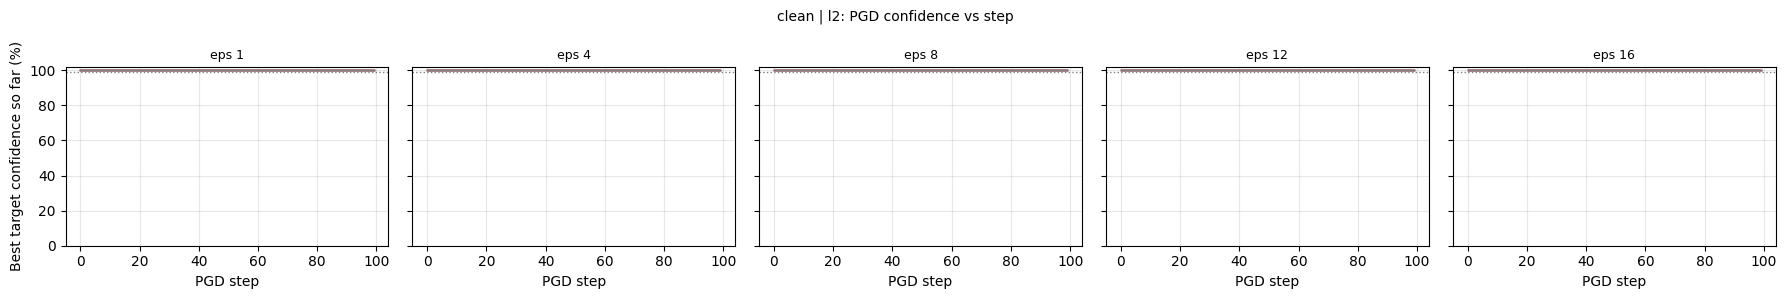

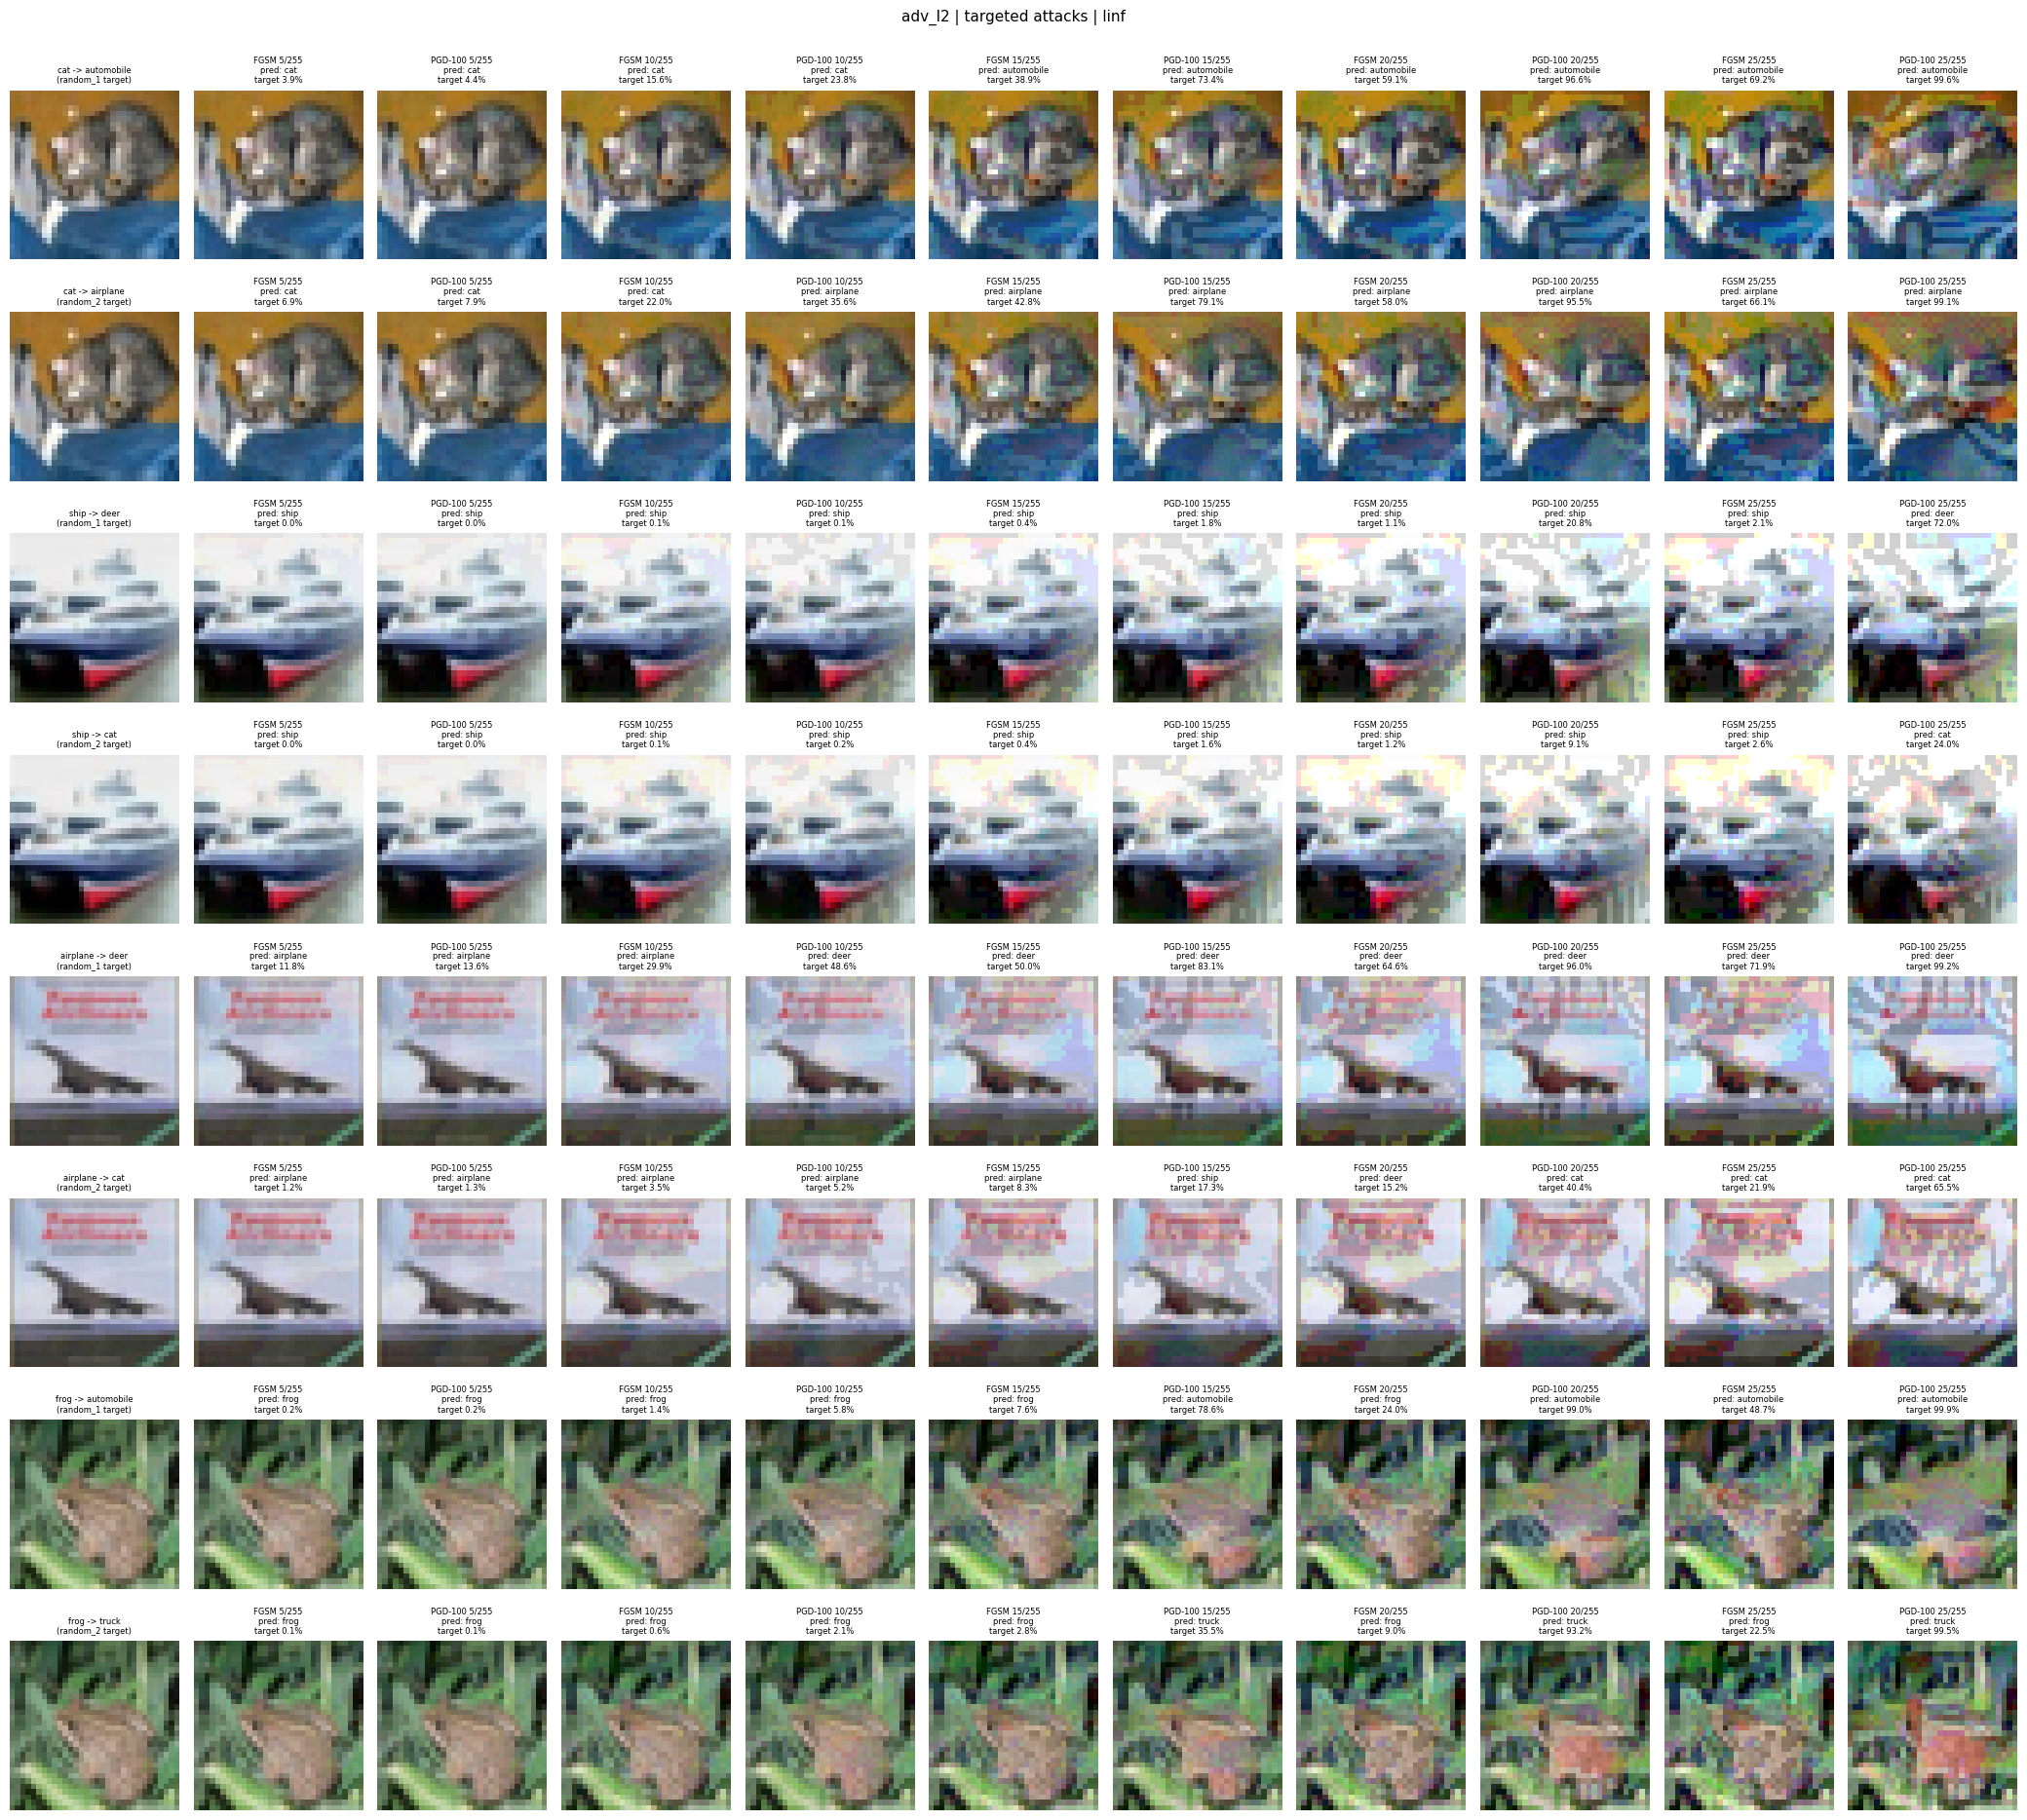

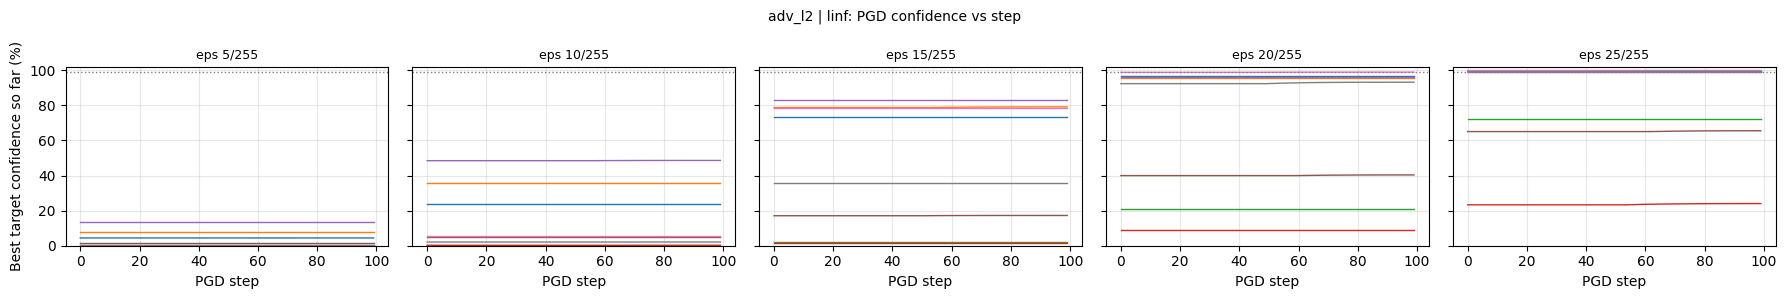

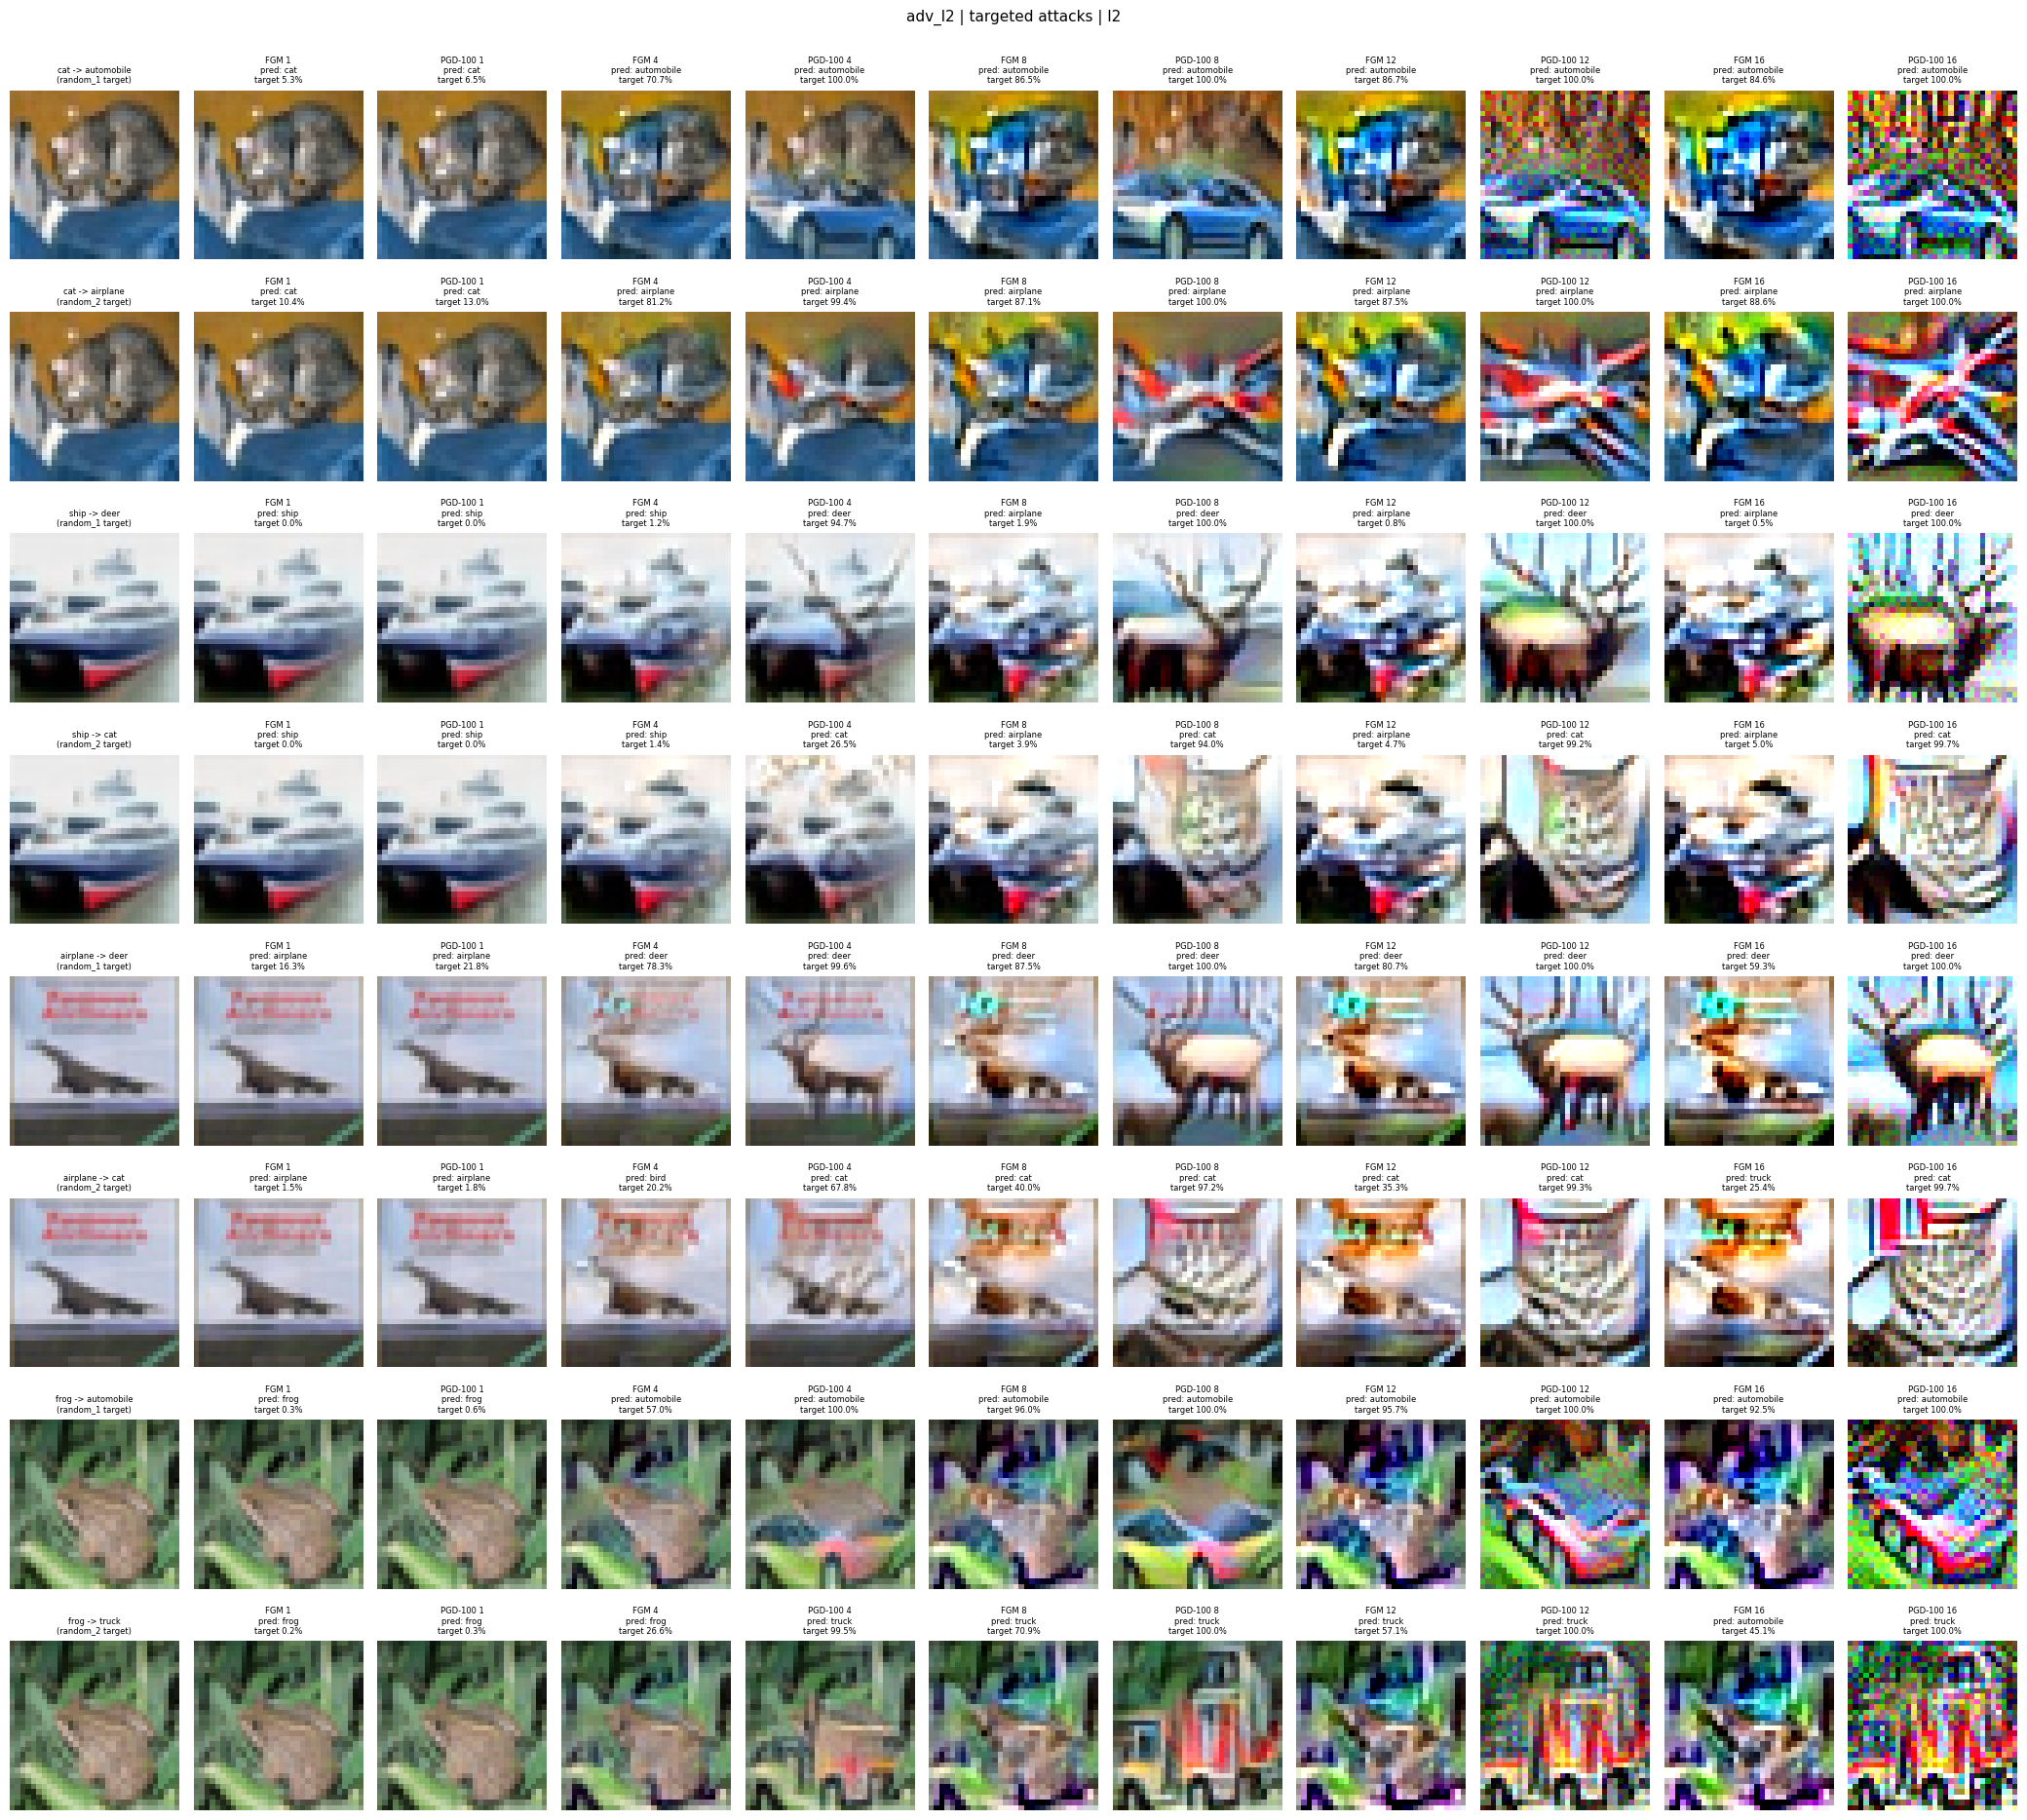

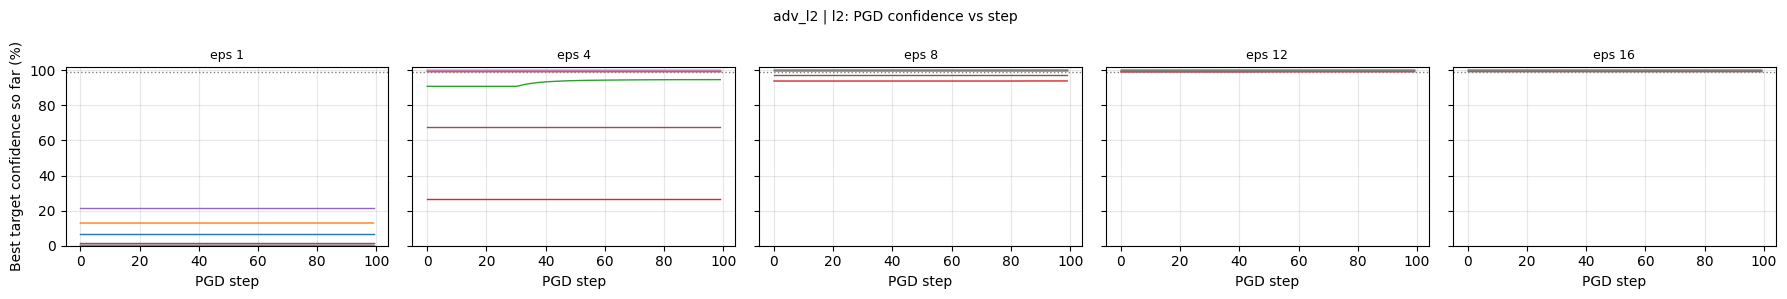

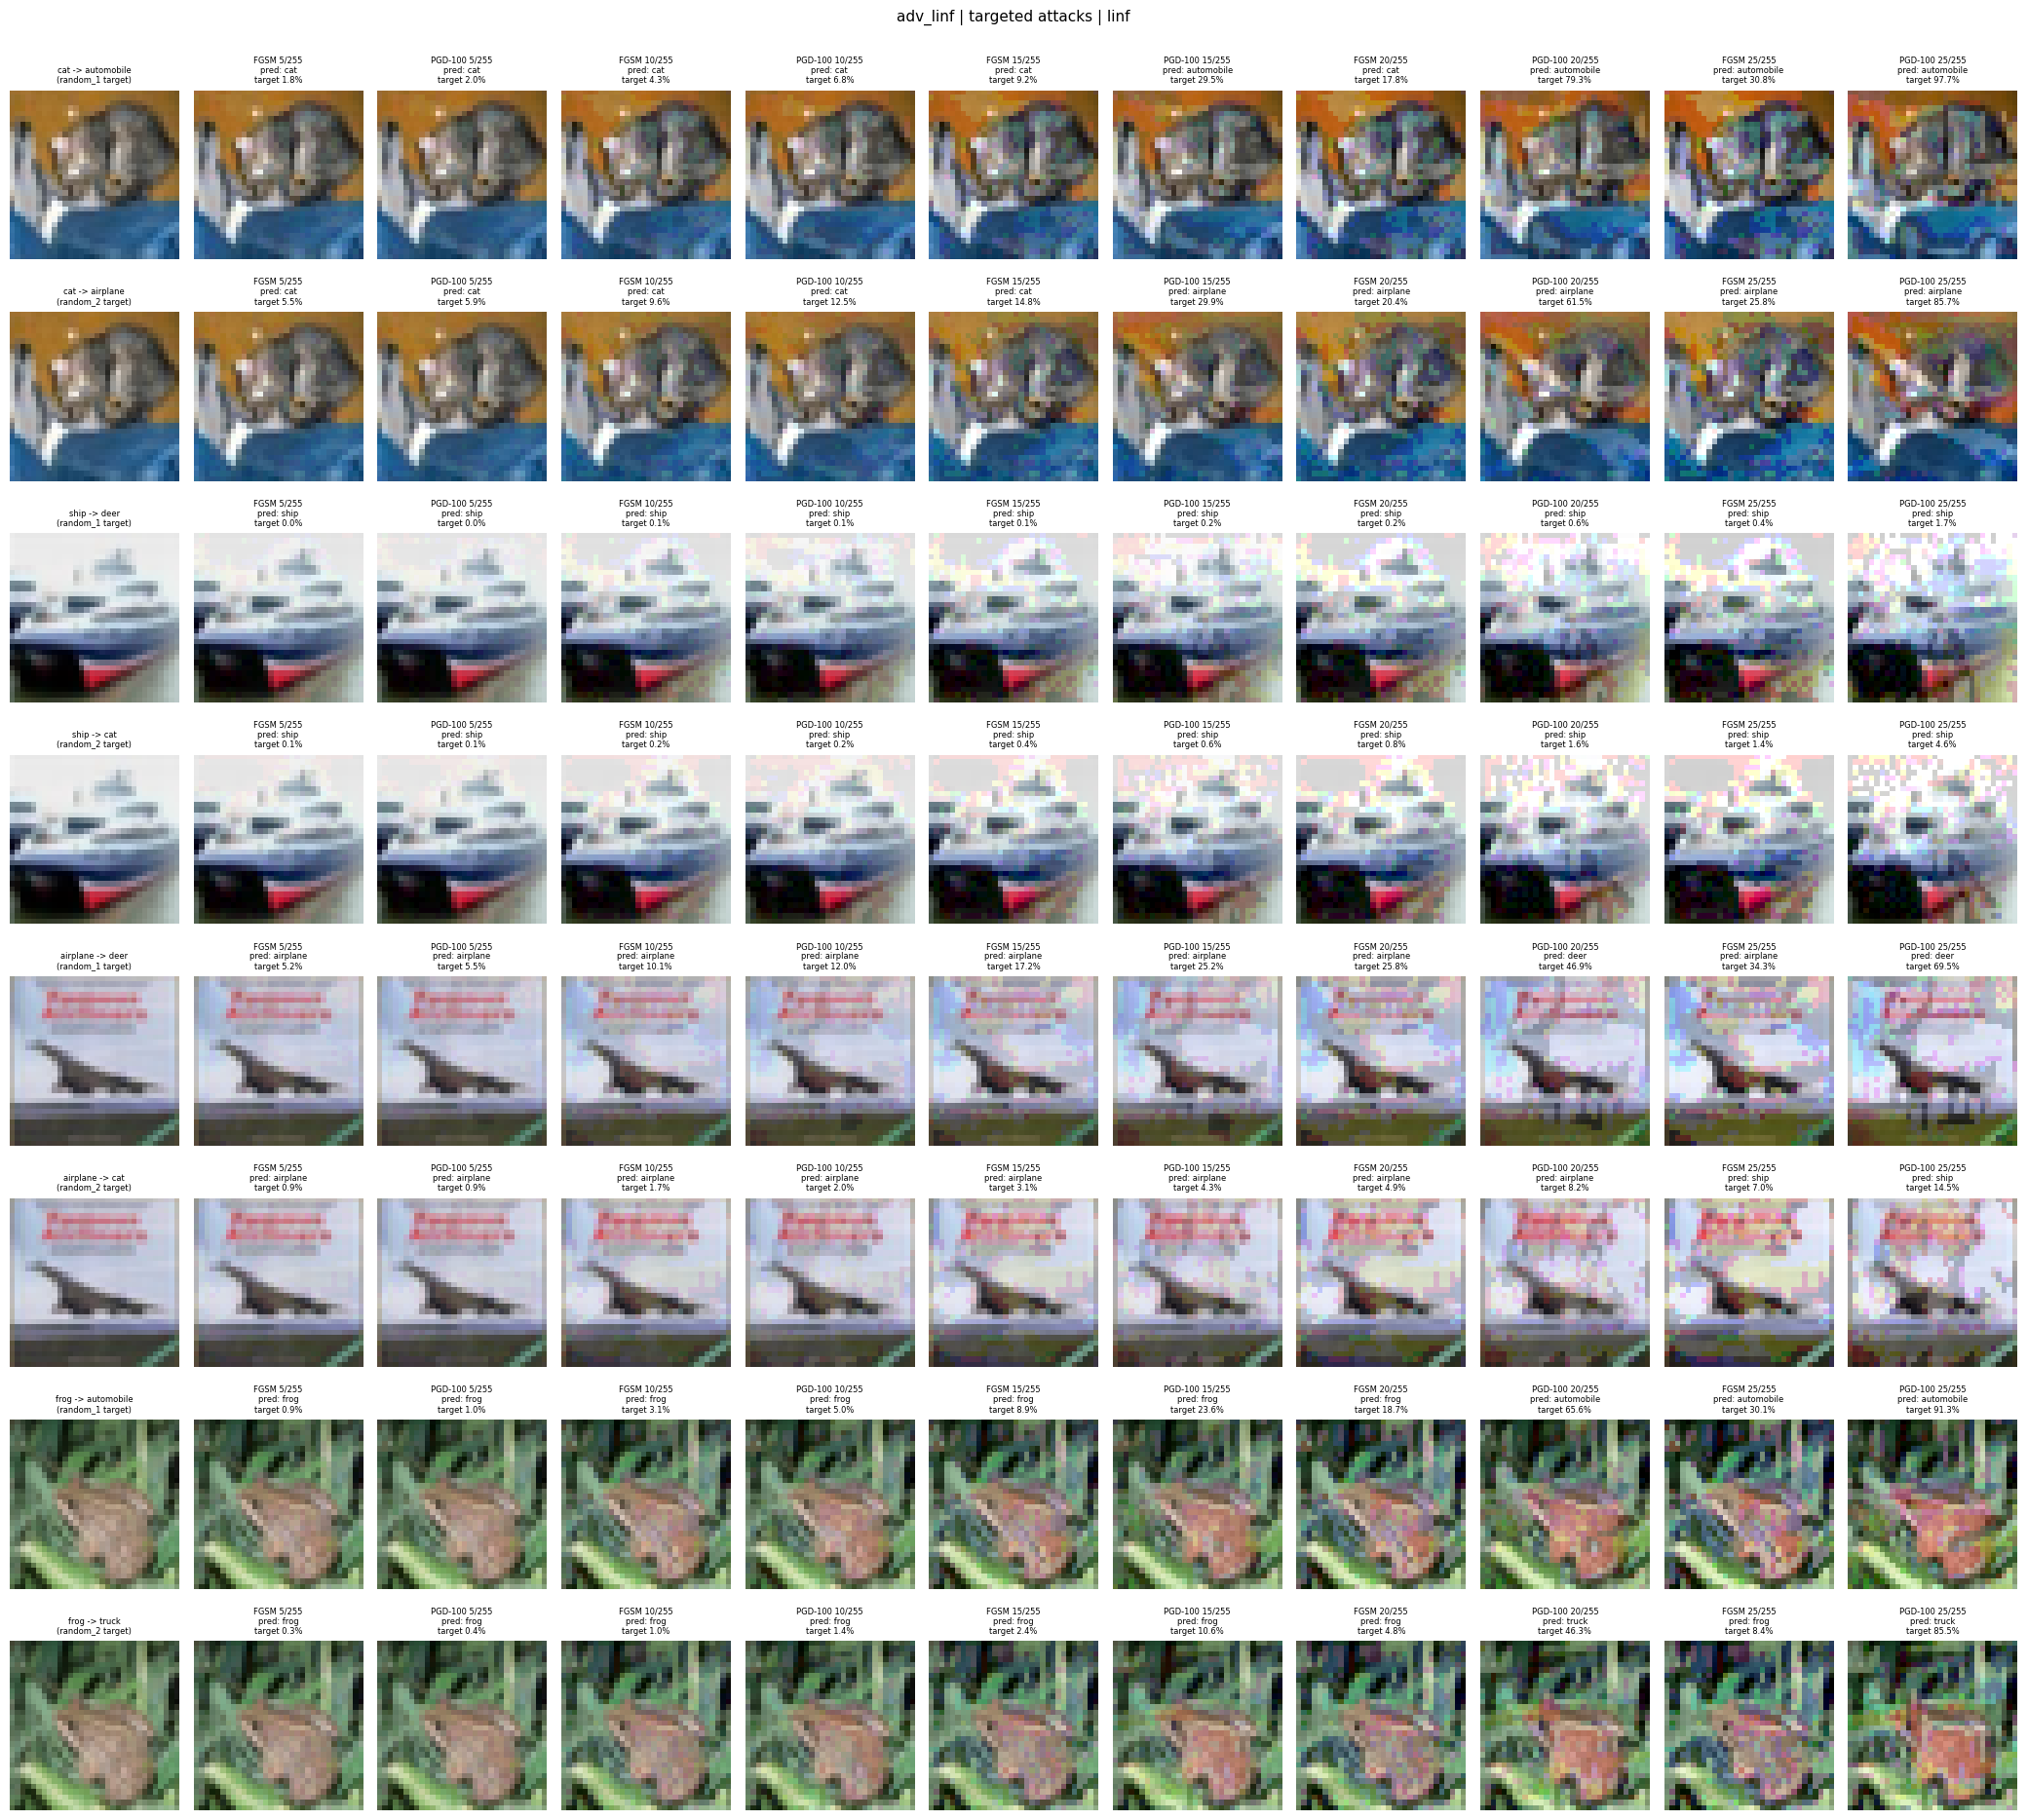

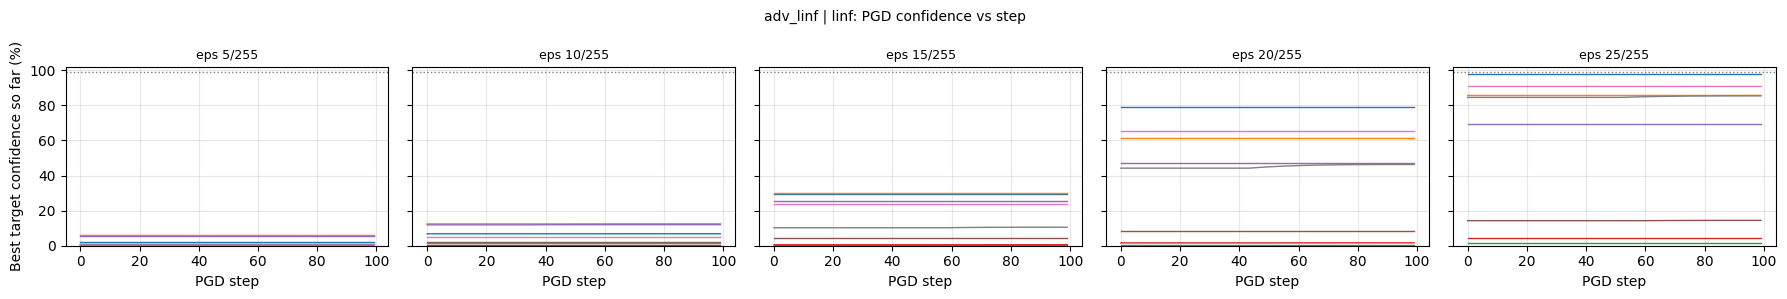

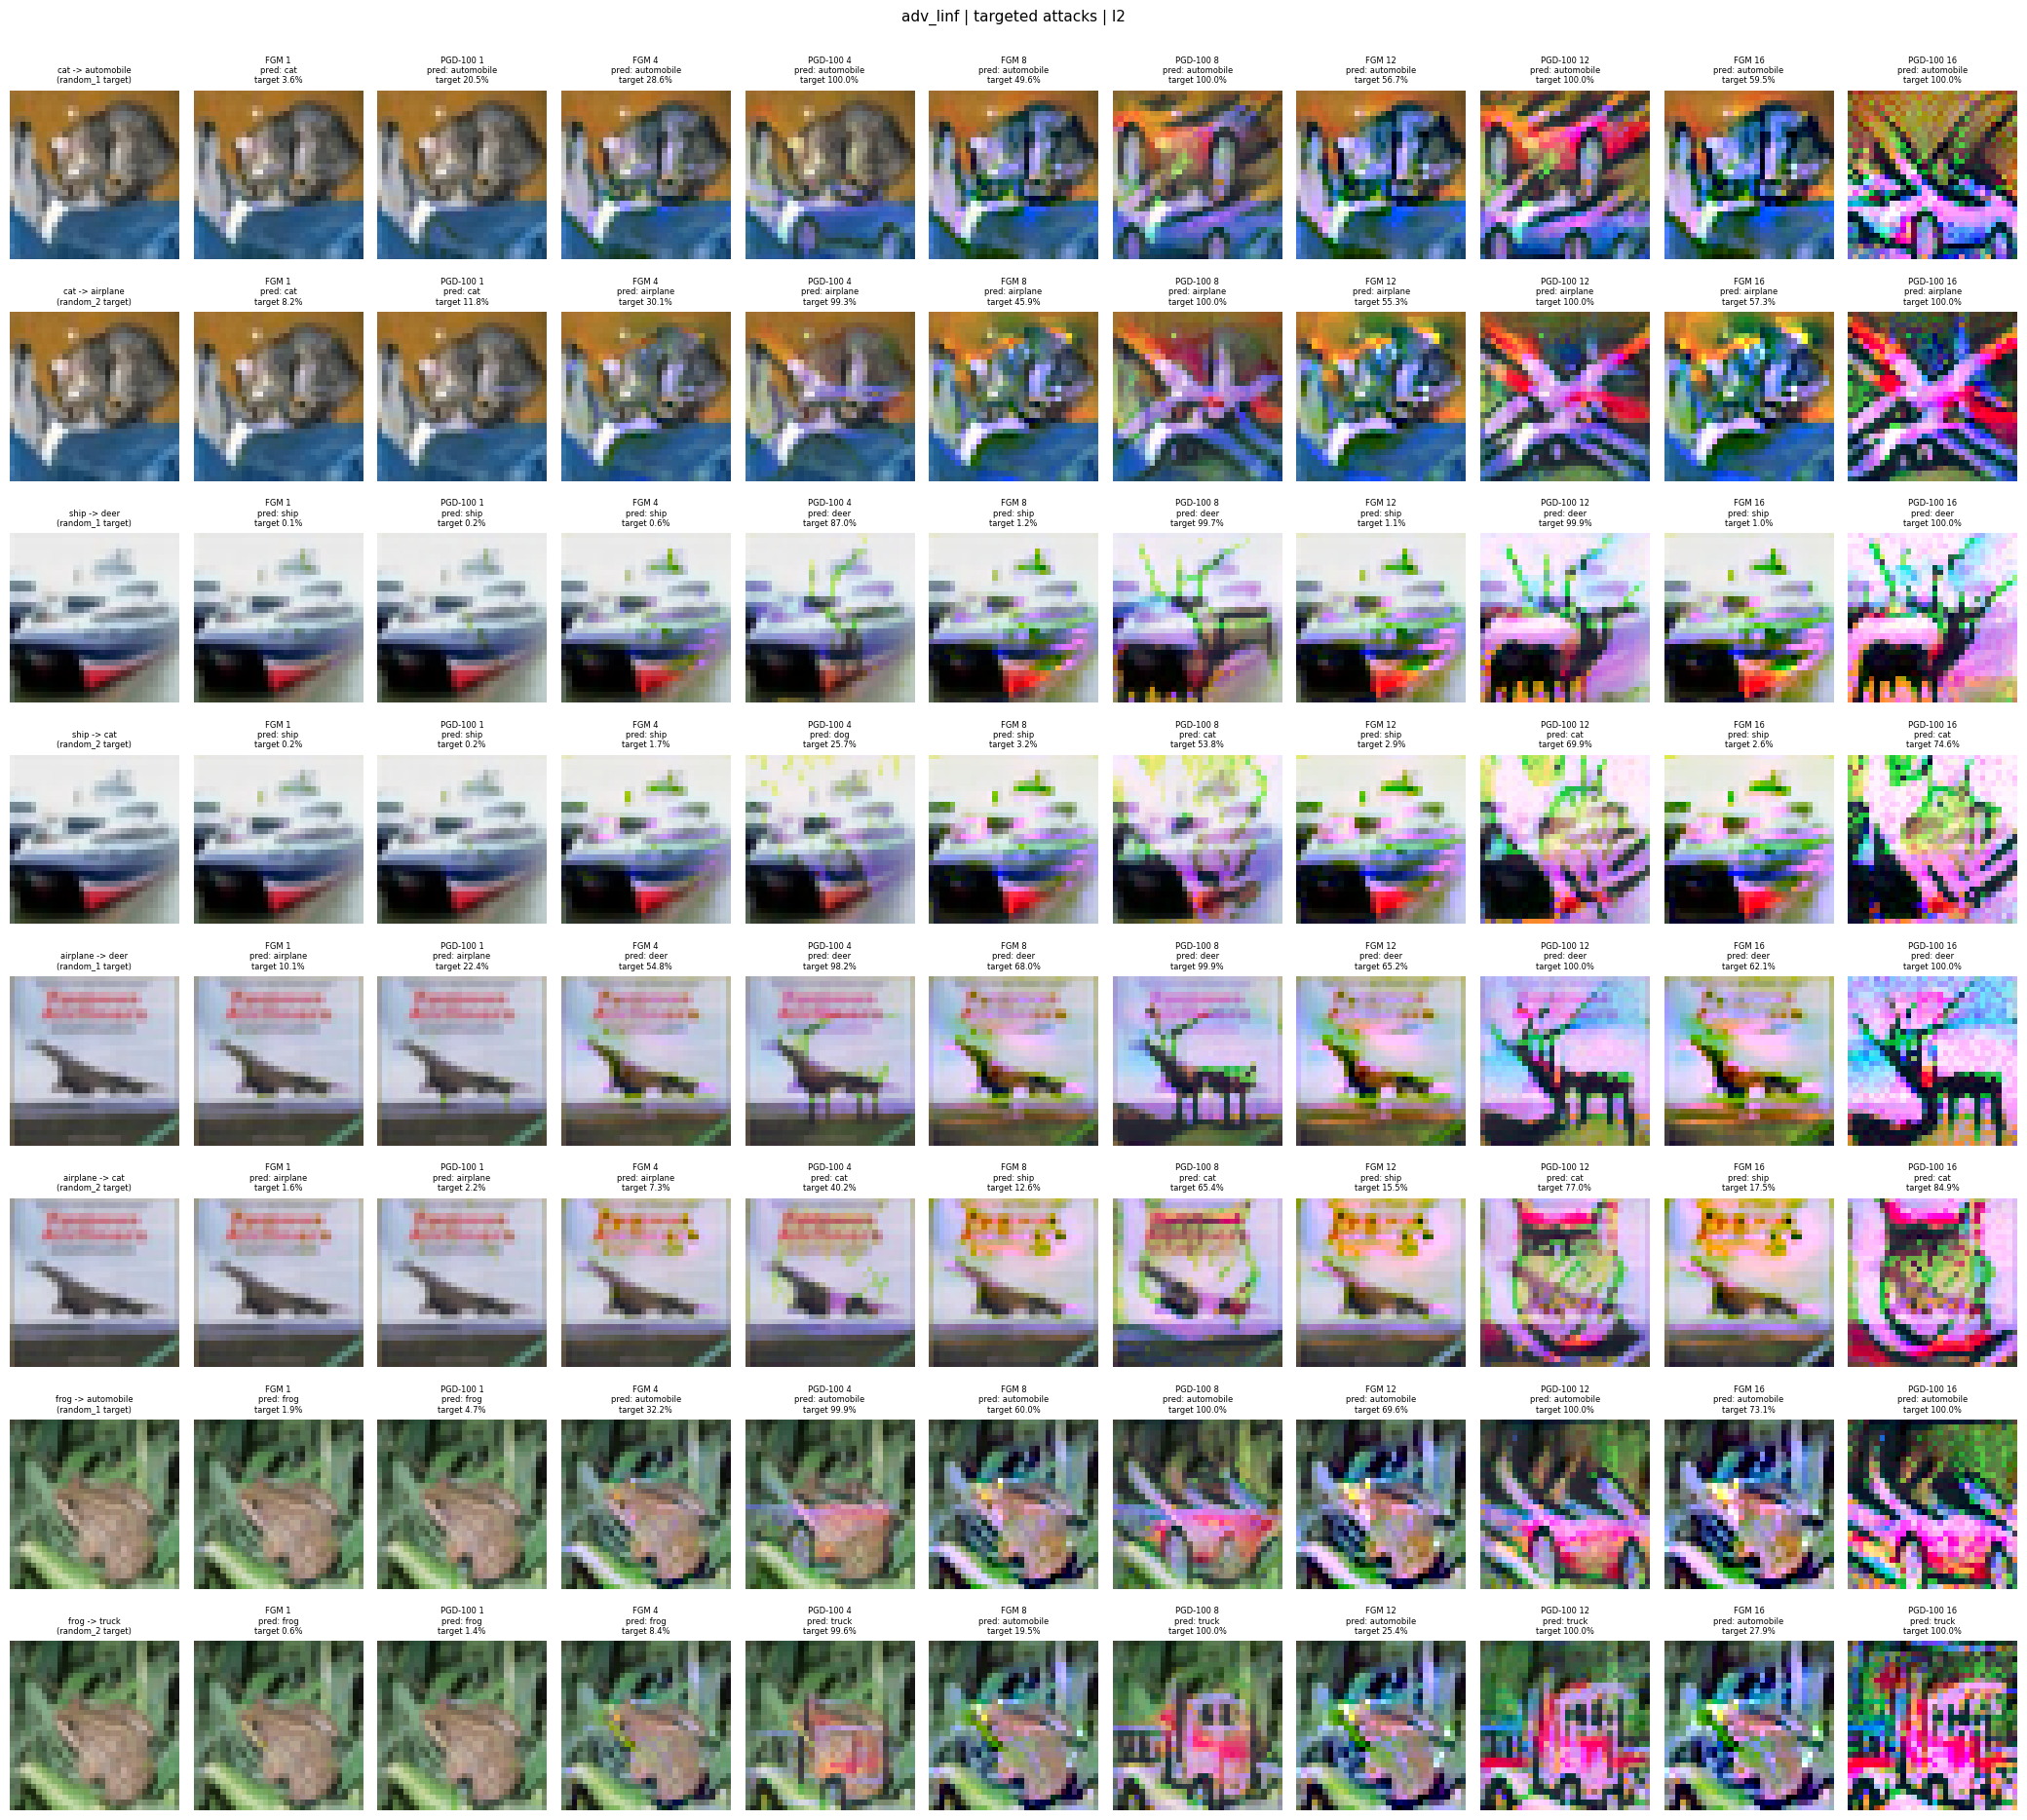

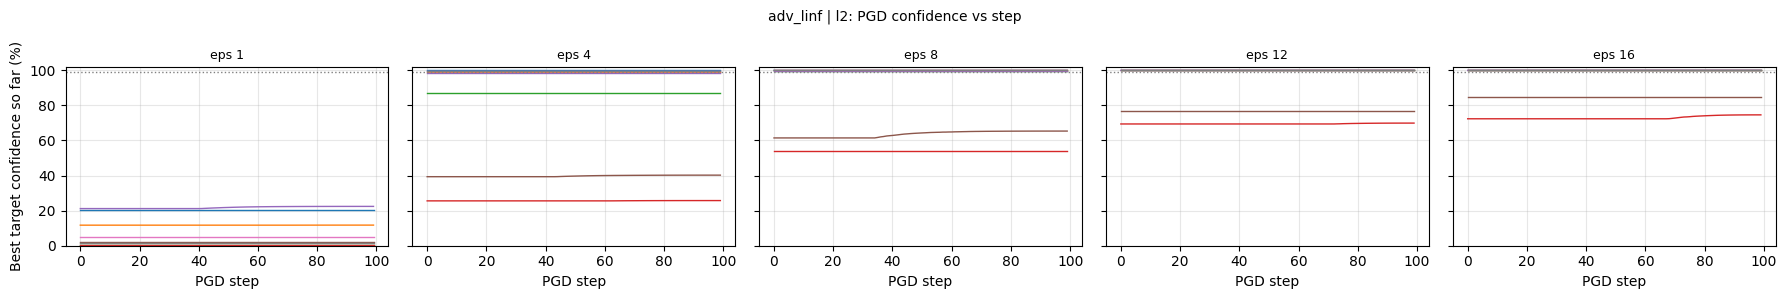

In [12]:
plot_confidence_vs_epsilon(table)

for mode in TRAINING_MODES:
    for norm in NORMS:
        plot_adversarial_grid(table, pairs, study_images, adv_store, mode, norm)
        plot_trajectories(traj_store, mode, norm)

## 13. Output check

Results are written to `RESULTS_DIR / confidence_study`. After this cell, use **Save Version** with outputs enabled.

In [13]:
for path in sorted(STUDY_DIR.rglob('*')):
    if path.is_file():
        print(f'{path.stat().st_size / 1024:9.1f} KB | {path}')

     61.0 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/confidence_study.csv
      2.1 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/confidence_summary.csv
     71.0 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/confidence_vs_eps_l2.png
     72.0 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/confidence_vs_eps_linf.png
    506.7 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/grid_adv_l2_l2.png
    373.1 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/grid_adv_l2_linf.png
    496.0 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/grid_adv_linf_l2.png
    376.0 KB | /kaggle/working/resnet20_targeted_attack_only/results/attack_sweeps/20261008_141842/grid_adv_linf_linf.png
    532.3 KB | /kaggle/worki

## Notes

All test-time attacks are targeted and maximize `log p(target)`. The wrong
targets are the easiest and hardest wrong classes under the clean model, so the
same sample-target pairs are used for all three models. Epsilons for Linf are in
units of 1/255. A model that was adversarially trained at a smaller budget will
usually need a larger epsilon to reach 99% confidence; that is a result, not a bug.